In [1]:
import pandas as pd
import numpy as np
from skimpy import clean_columns
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from datetime import datetime
import scipy.stats as stats
import scikit_posthocs as sp
from scipy.stats import pearsonr

/Users/chloecho/anaconda3/envs/cornell_dev/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [153]:
deli_cup_25 = pd.read_csv('Data/2025/deli_cup_2025.csv')
deli_cup_25 = clean_columns(deli_cup_25)
deli_cup_25['scm_total'] = deli_cup_25['scm_larvae_sum'] + deli_cup_25['scm_pupae_sum']
deli_cup_25['scm_per_seed'] = deli_cup_25['scm_total'] / deli_cup_25['number_seeds']
deli_cup_25['prop_seeds'] = deli_cup_25['scm_seed'] / deli_cup_25['number_seeds']
deli_cup_25['treatment'] = deli_cup_25['treatment'].replace({'FUNG': 'Fungicide', 'NEONIC': 'Neonicotinoid'})
deli_cup_25['seed_type'] = deli_cup_25['seed_type'].replace({'FIELD CORN': 'Field corn', 'SOY': 'Soybean', 'SWEET CORN': 'Sweet corn', 'SNAP': 'Snap bean'})
deli_cup_25 = deli_cup_25.loc[(deli_cup_25['seed_type'] == 'Field corn') | (deli_cup_25['seed_type'] == 'Soybean')]
deli_cup_25

,container_number,container_type,project,field_id,treatment,collection_date,seed_type,number_seeds,scm_larvae_sum,scm_pupae_sum,...,wireworms,other_seeds,wireworm_presence_absence,grub_presence_absence,checked,ordered_entered,notes,scm_total,scm_per_seed,prop_seeds
0,25_D_1181,DELI,R,CER_DEL_1,Neonicotinoid,5/28/25,Field corn,14.0,1,0,...,3,0,YES,YES,Y,294,NaN,1,0.071429,0.000000
1,25_D_1182,DELI,R,CER_DEL_1,Fungicide,5/28/25,Field corn,14.0,0,0,...,0,0,NO,NO,Y,293,NaN,0,0.000000,0.000000
2,25_D_1183,DELI,R,CER_DEL_1,Neonicotinoid,5/28/25,Field corn,17.0,2,0,...,0,0,NO,NO,Y,380,NaN,2,0.117647,0.000000
3,25_D_1184,DELI,R,CER_DEL_1,Neonicotinoid,5/28/25,Field corn,15.0,0,0,...,0,0,NO,NO,Y,308,NaN,0,0.000000,0.000000
4,25_D_1185,DELI,R,CER_DEL_1,Fungicide,5/28/25,Field corn,15.0,2,0,...,0,0,NO,NO,Y,51,NaN,2,0.133333,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,25_D_1158,DELI,R,STA_WOO,Fungicide,5/23/25,Field corn,15.0,1,1,...,1,1,YES,NO,Y,15,NaN,2,0.133333,0.066667
946,25_D_1159,DELI,R,STA_WOO,Neonicotinoid,5/23/25,Field corn,15.0,0,0,...,0,0,NO,NO,Y,296,NaN,0,0.000000,0.000000
947,25_D_1160,DELI,R,STA_WOO,Neonicotinoid,5/23/25,Field corn,15.0,0,0,...,0,0,NO,NO,Y,295,NaN,0,0.000000,0.000000
948,25_D_1161,DELI,R,STA_WOO,Fungicide,5/23/25,Field corn,15.0,3,0,...,0,1,NO,NO,Y,3,NaN,3,0.200000,0.066667


In [203]:
grouped = deli_cup_25.groupby(['field_id', 'treatment'])['scm_per_seed'].agg(mean='mean', sem='sem').reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values=['mean', 'sem'])

diff_df = pd.DataFrame()
diff_df['diff_mean'] = grouped['mean']['Neonicotinoid'] - grouped['mean']['Fungicide']

se_neonic = grouped['sem']['Neonicotinoid']
se_fung = grouped['sem']['Fungicide']
diff_df['se_diff'] = np.sqrt(se_neonic**2 + se_fung**2)

diff_df = diff_df.reset_index()
diff_df = diff_df.sort_values('diff_mean')
diff_df = pd.merge(diff_df, deli_cup_25[['field_id', 'seed_type']], on='field_id', how='left').drop_duplicates()
diff_df.head()

,field_id,diff_mean,se_diff,seed_type
0,STA_WOO,-0.246032,0.061445,Field corn
18,DEG_PER_2,-0.194421,0.164114,Soybean
36,SMI_DOU,-0.134442,0.082323,Soybean
54,HUN_REE,-0.086111,0.031187,Soybean
72,SMI_LAT,-0.077459,0.039419,Field corn


In [205]:
diff_df['seed_type'].value_counts()

seed_type
Field corn    33
Soybean       16
Name: count, dtype: int64

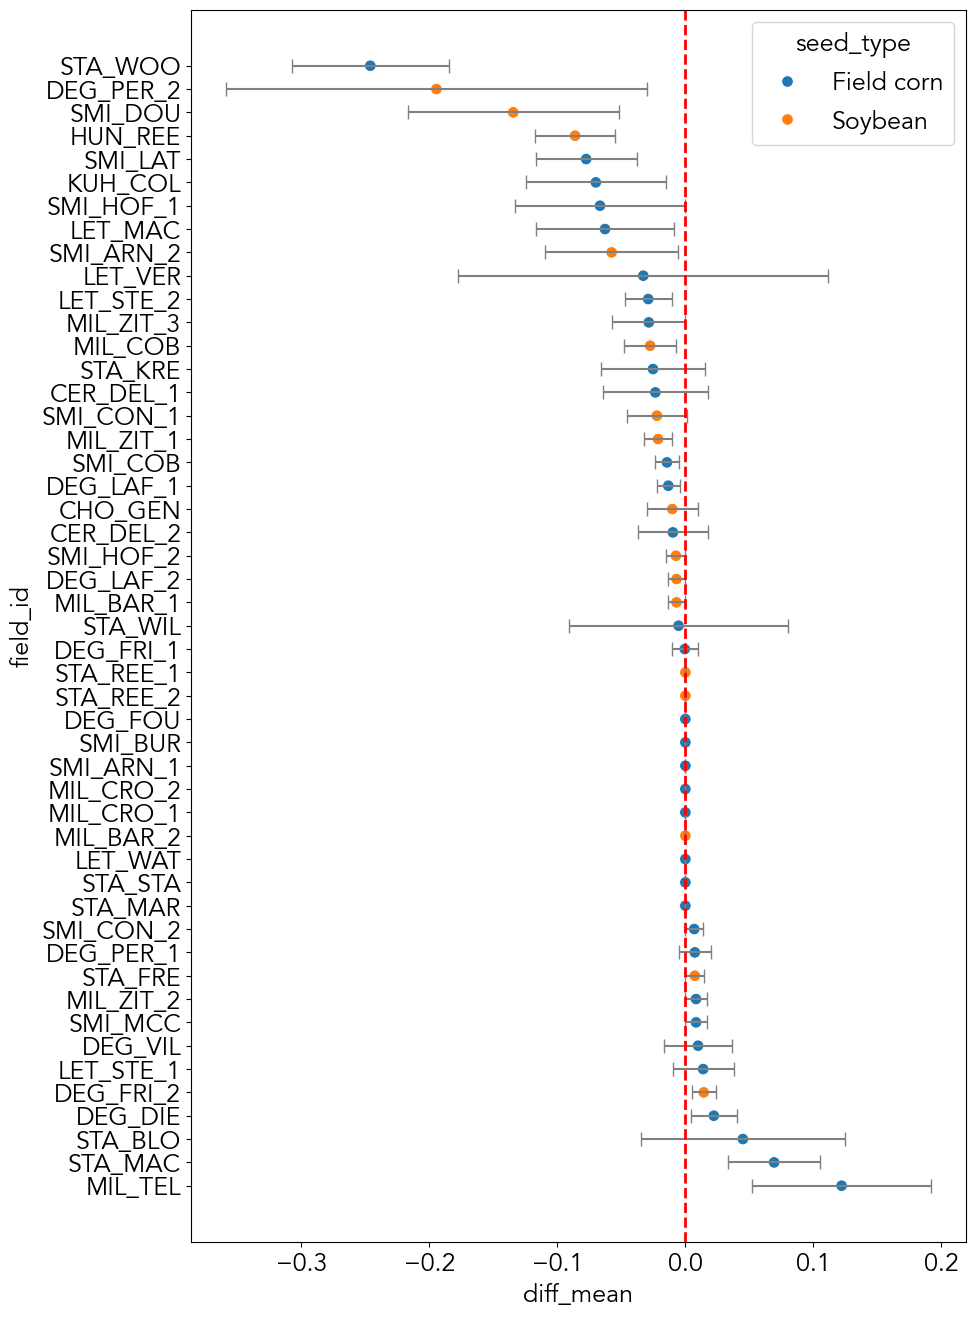

In [194]:
plt.figure(figsize=(10, 16))

plt.errorbar(diff_df['diff_mean'], diff_df['field_id'], xerr=diff_df['se_diff'], fmt="None", capsize=5, ecolor='grey')
sns.scatterplot(data=diff_df, x="diff_mean", y="field_id", hue='seed_type', s=70)
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


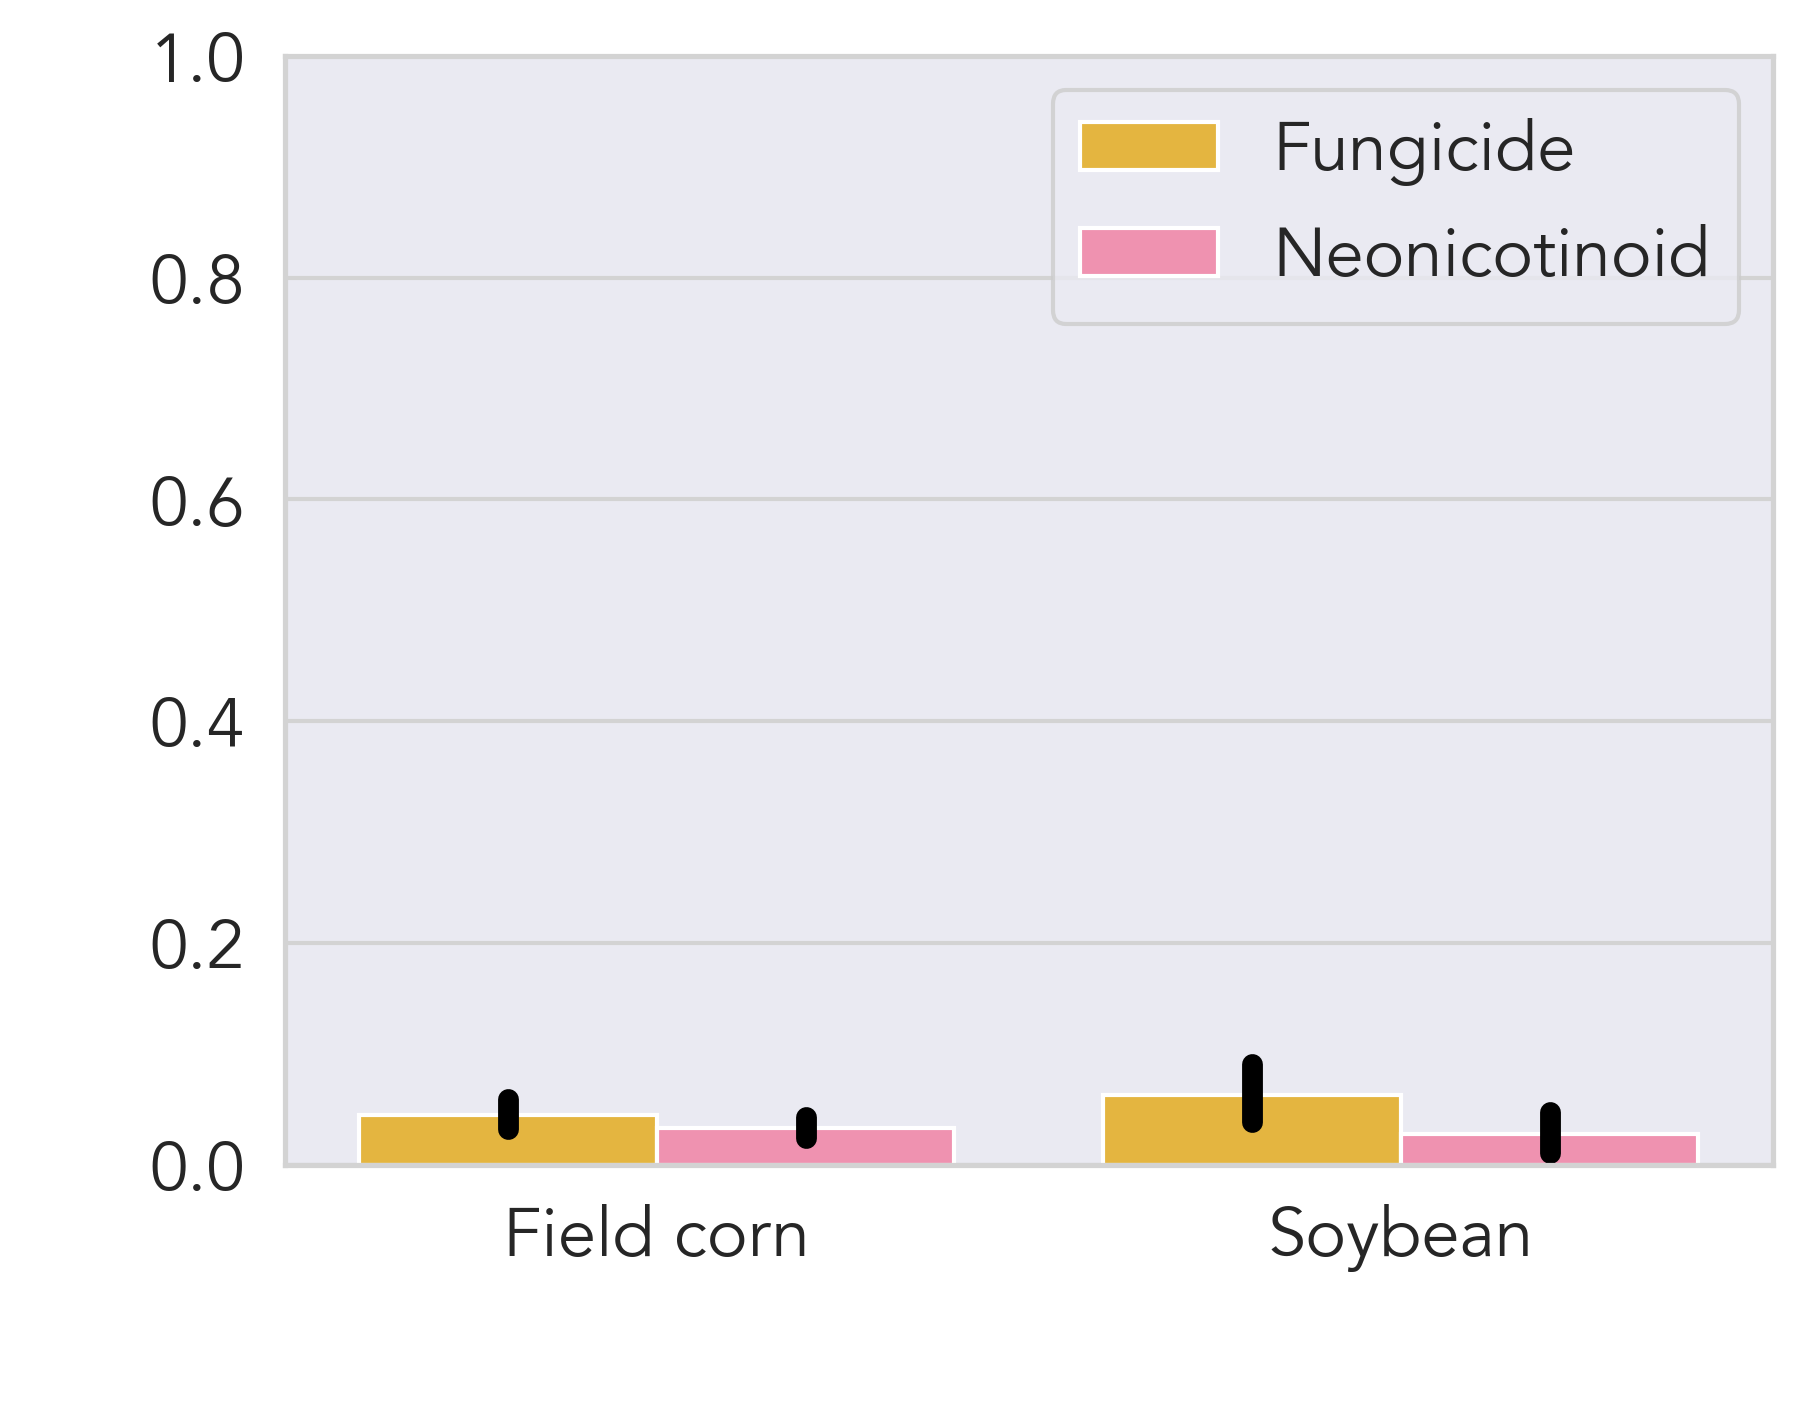

In [286]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

ax = sns.barplot(
    data=deli_cup_25,
    x="seed_type",
    y="scm_per_seed",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)

plt.xlabel(" ", labelpad=10)
plt.ylabel(" ", labelpad=10)
plt.ylim(0, 1)
plt.show()


In [312]:
t1 = deli_cup_25.loc[(deli_cup_25['treatment'] == 'Neonicotinoid') & (deli_cup_25['seed_type'] == 'Field corn')].groupby('field_id')['scm_per_seed'].mean()
t2 = deli_cup_25.loc[(deli_cup_25['treatment'] == 'Fungicide') & (deli_cup_25['seed_type'] == 'Field corn')].groupby('field_id')['scm_per_seed'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-1.2063759627417392, pvalue=0.2365160321667272, df=32)

In [313]:
t1 = deli_cup_25.loc[(deli_cup_25['treatment'] == 'Neonicotinoid') & (deli_cup_25['seed_type'] == 'Soybean')].groupby('field_id')['scm_per_seed'].mean()
t2 = deli_cup_25.loc[(deli_cup_25['treatment'] == 'Fungicide') & (deli_cup_25['seed_type'] == 'Soybean')].groupby('field_id')['scm_per_seed'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.4037548596545326, pvalue=0.029606804944199493, df=15)

In [371]:
stand_2025 = pd.read_csv('Data/2025/stand_loss_2025.csv')
stand_2025 = clean_columns(stand_2025)
stand_2025['treatment'] = stand_2025['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})
stand_2025 = stand_2025.loc[(stand_2025['crop'] == 'Field corn') | (stand_2025['crop'] == 'Soybean')]

stand_ny_2025 = stand_2025.loc[stand_2025['state'] == 'New York']

stand_2025

,data_collector,state,field_id,date,sampling_period,crop,treatment,section_number,plant_growth_stage,stand_count,notes
0,Paul Cerosaletti,New York,CER_DEL_1,6/16/25,VE/V1,Field corn,Neonicotinoid,1,VE/V1,29.0,NaN
1,Paul Cerosaletti,New York,CER_DEL_1,6/16/25,VE/V1,Field corn,Neonicotinoid,2,VE/V1,30.0,NaN
2,Paul Cerosaletti,New York,CER_DEL_1,6/16/25,VE/V1,Field corn,Neonicotinoid,3,VE/V1,24.0,NaN
3,Paul Cerosaletti,New York,CER_DEL_1,6/16/25,VE/V1,Field corn,Neonicotinoid,4,VE/V1,29.0,NaN
4,Paul Cerosaletti,New York,CER_DEL_1,6/16/25,VE/V1,Field corn,Neonicotinoid,5,VE/V1,28.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2281,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,5,V3/V4,16.0,NaN
2282,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,6,V3/V4,17.0,NaN
2283,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,7,V3/V4,19.0,NaN
2284,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,8,V3/V4,33.0,NaN


In [214]:
grouped = stand_2025.groupby(['field_id', 'treatment'])['stand_count'].agg(mean='mean', sem='sem').reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values=['mean', 'sem'])

diff_df = pd.DataFrame()
diff_df['diff_mean'] = grouped['mean']['Neonicotinoid'] - grouped['mean']['Fungicide']

se_neonic = grouped['sem']['Neonicotinoid']
se_fung = grouped['sem']['Fungicide']
diff_df['se_diff'] = np.sqrt(se_neonic**2 + se_fung**2)

diff_df = diff_df.reset_index()
diff_df = diff_df.sort_values('diff_mean')
diff_df = pd.merge(diff_df, stand_2025[['field_id', 'crop']], on='field_id', how='left').drop_duplicates()

diff_df.head()

,field_id,diff_mean,se_diff,crop
0,MIL_BAR_1,-17.333333,3.964256,Soybean
36,KUH_COL,-16.055556,1.766354,Field corn
72,GER_C,-14.888889,1.772050,Field corn
108,MIL_BAR_2,-12.722222,6.305134,Soybean
144,MAC_S,-11.777778,7.001738,Soybean


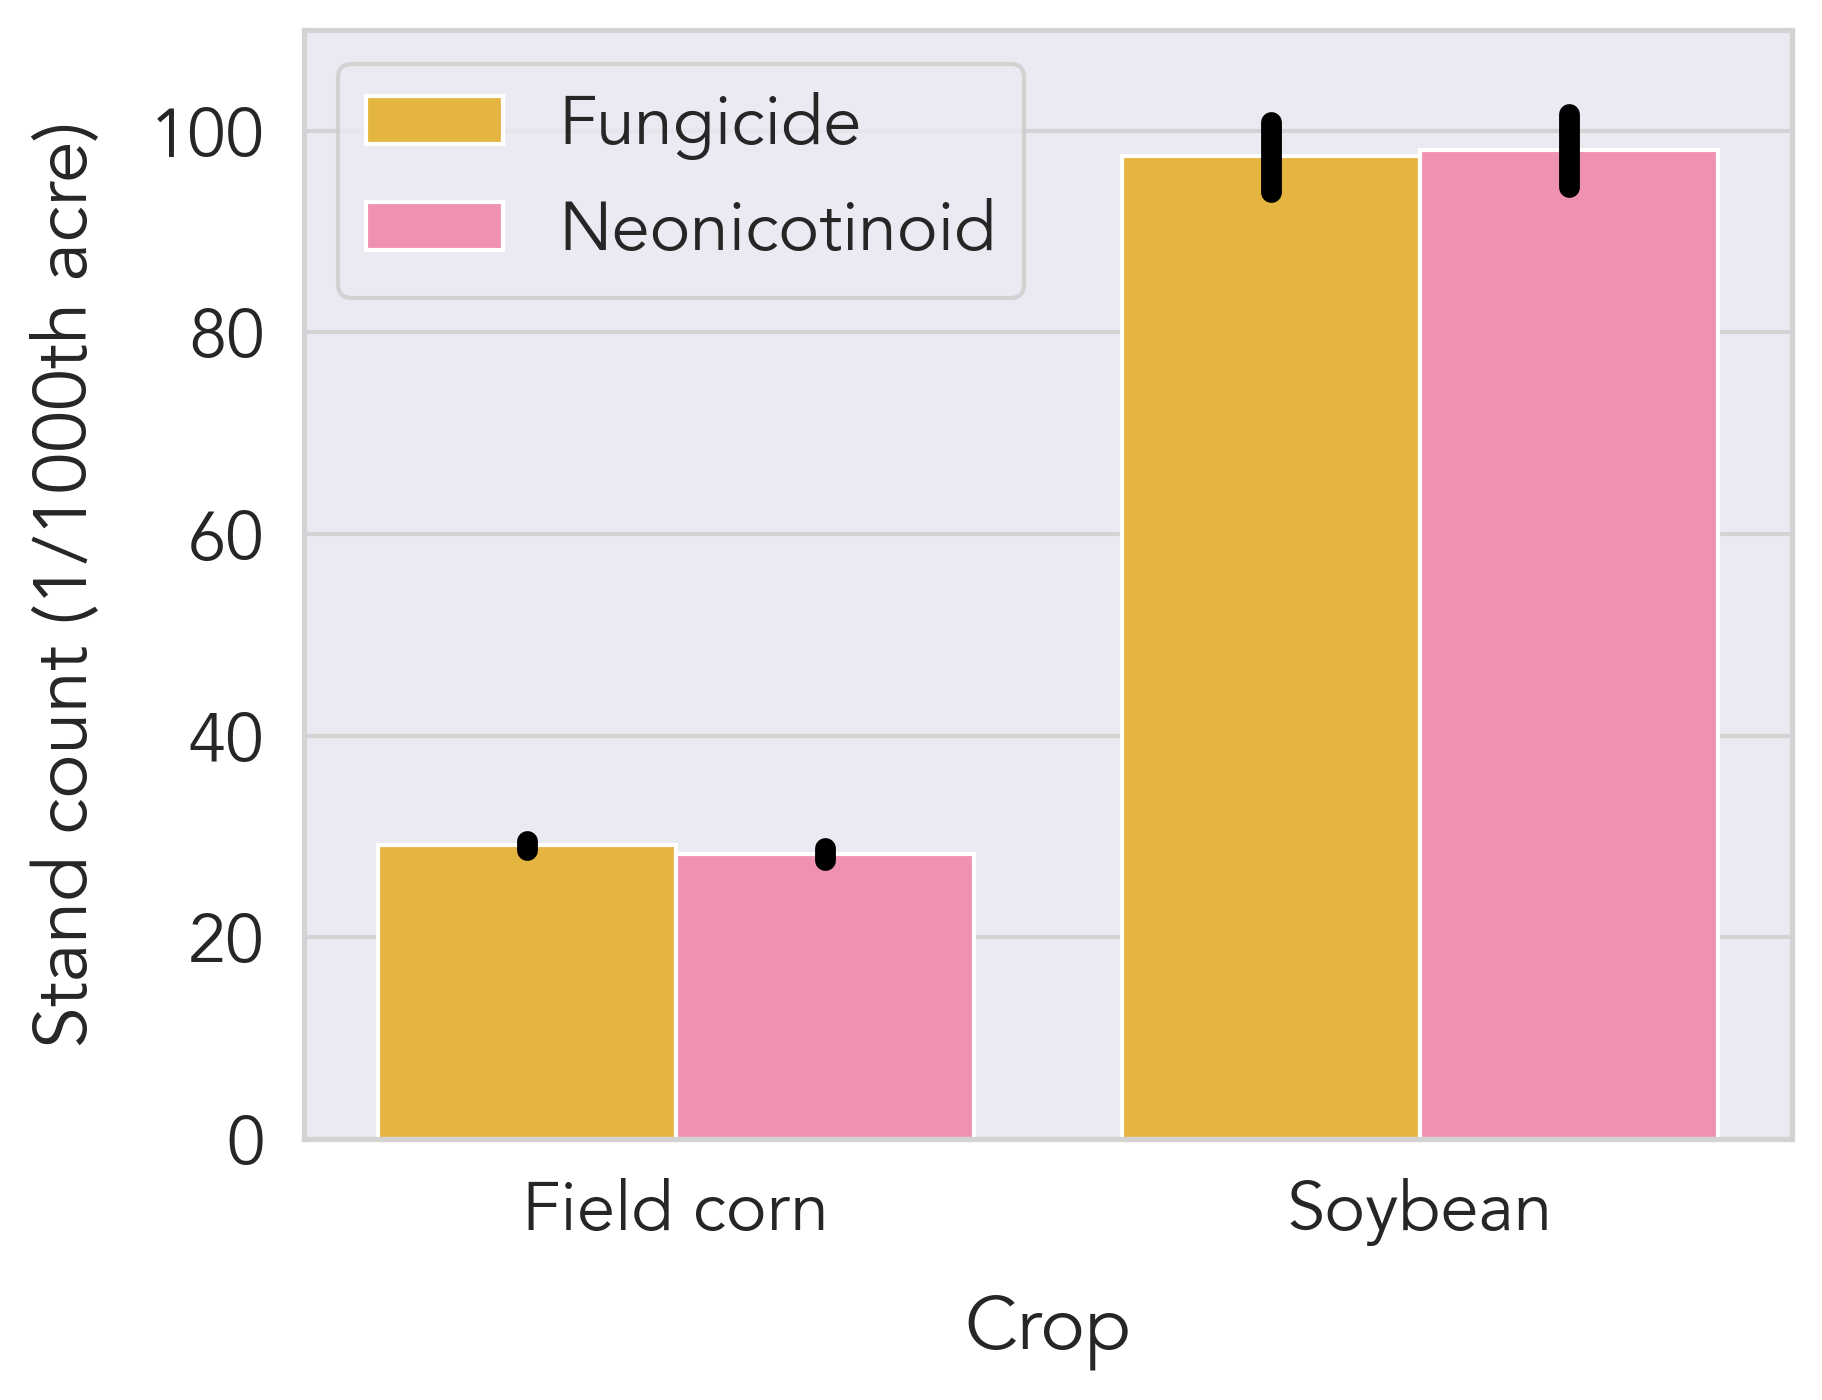

In [433]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

ax = sns.barplot(
    data=stand_ny_2025,
    x="crop",
    y="stand_count",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)
plt.legend(loc='upper left')

plt.xlabel("Crop", labelpad=10)
plt.ylabel("Stand count (1/1000th acre)", labelpad=10)
plt.ylim(0, 110)
plt.show()


In [373]:
t1 = stand_2025.loc[(stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.3373310119878234, pvalue=0.024146612988344283, df=43)

In [374]:
t1 = stand_2025.loc[(stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.3670594176712072, pvalue=0.7178544760452124, df=18)

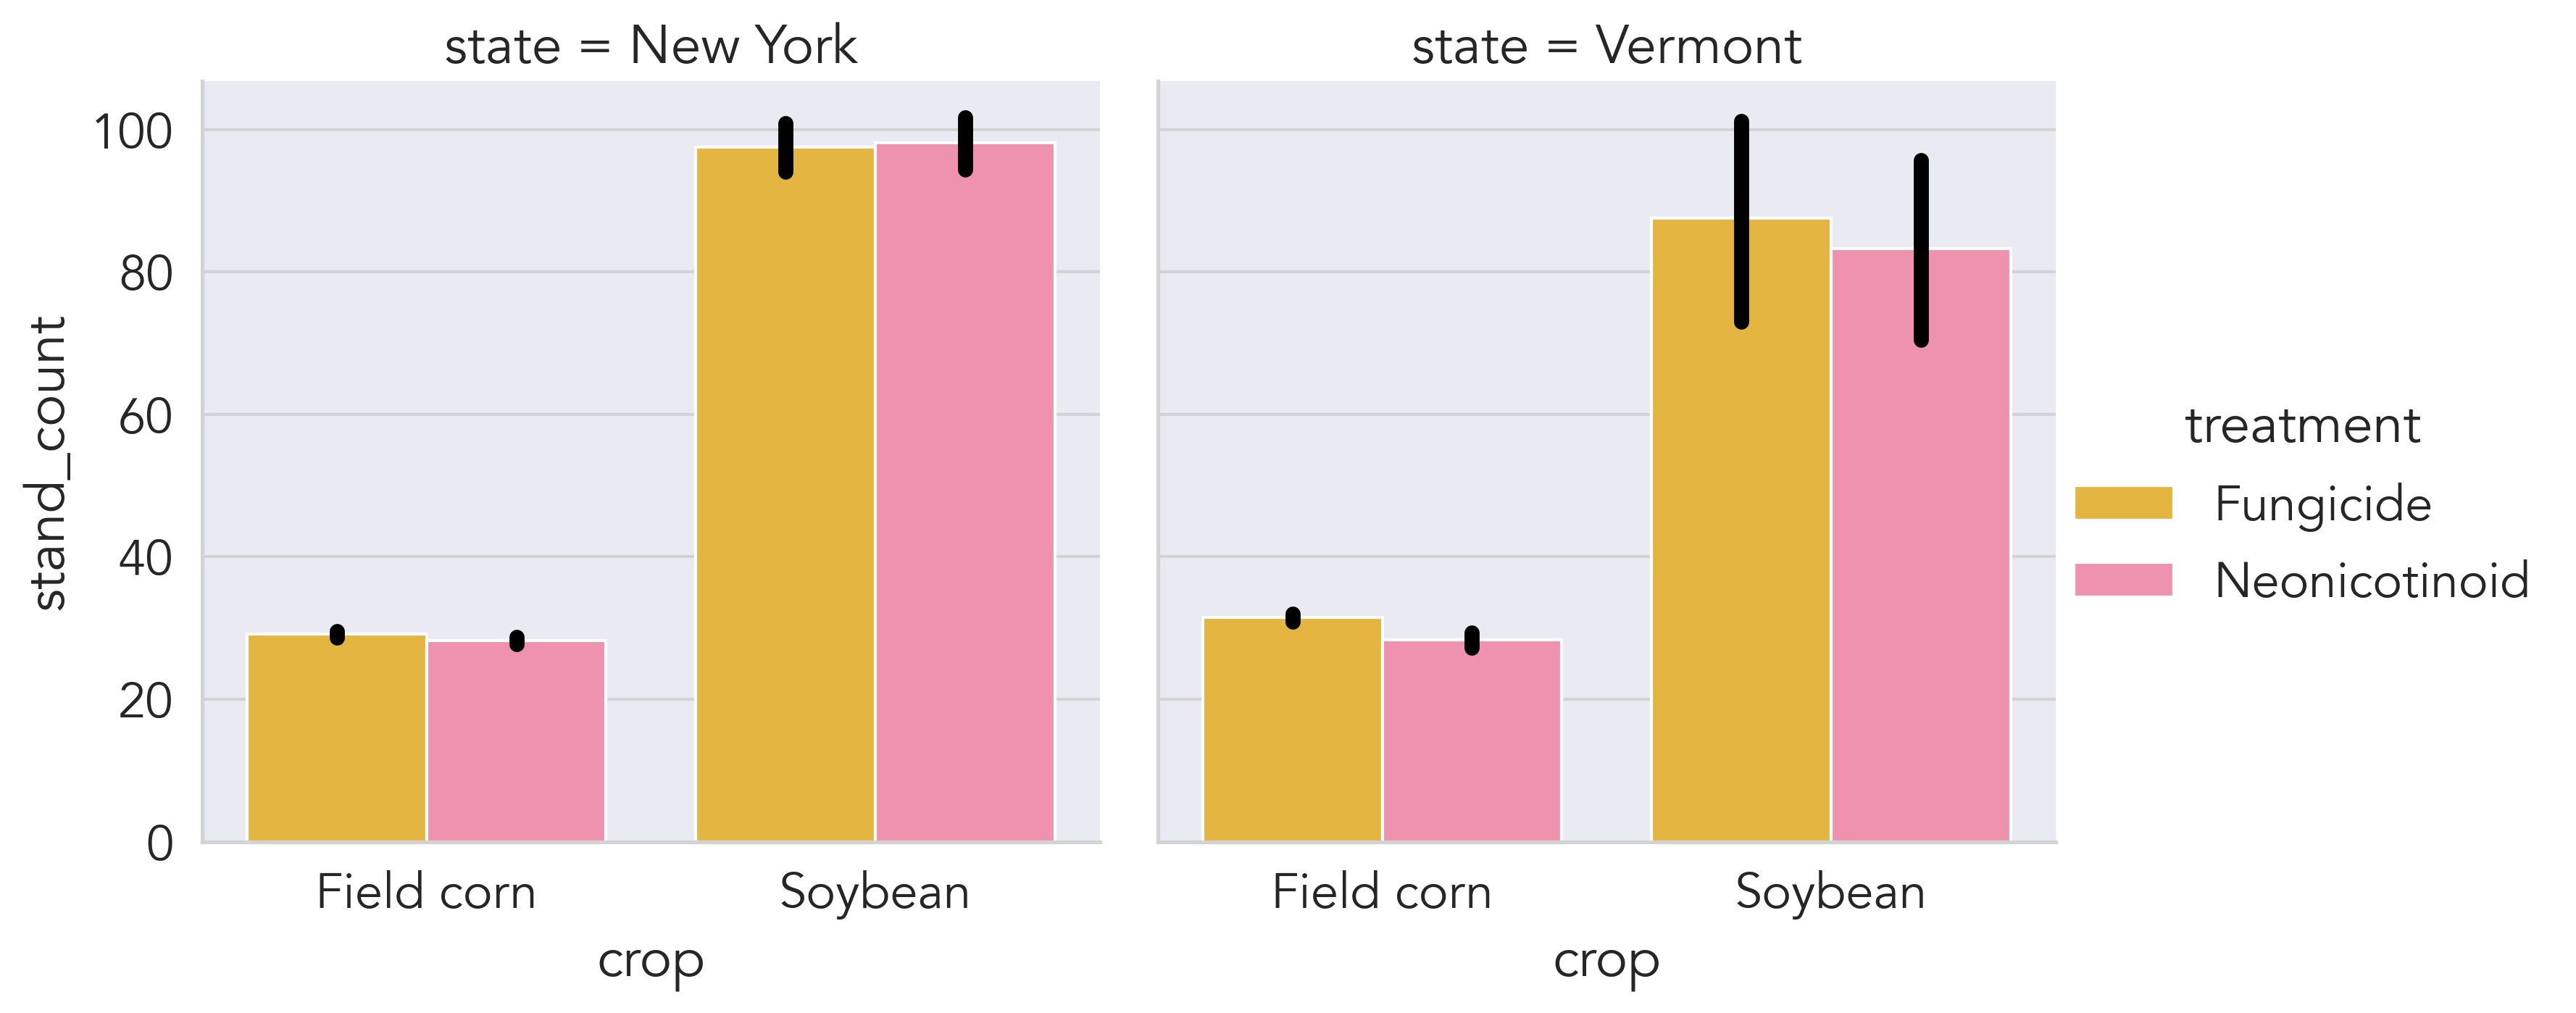

In [378]:
g = sns.catplot(
    data=stand_2025, 
    kind="bar", 
    x="crop", 
    y="stand_count", 
    hue="treatment",  # First Hue (Colors)
    col="state",     # Second Hue (Subplots)
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    err_kws={'linewidth': 5, 'color':'black'}
)

In [232]:
t1 = stand_2025.loc[(stand_2025['state'] == 'New York') & (stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['state'] == 'New York') & (stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-1.3185430953207606, pvalue=0.1966815718833915, df=32)

In [233]:
t1 = stand_2025.loc[(stand_2025['state'] == 'New York') & (stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['state'] == 'New York') & (stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.6513030634981642, pvalue=0.5247042610679078, df=15)

In [234]:
t1 = stand_2025.loc[(stand_2025['state'] == 'Vermont') & (stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['state'] == 'Vermont') & (stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.276260336214878, pvalue=0.04607771578162553, df=10)

In [235]:
t1 = stand_2025.loc[(stand_2025['state'] == 'Vermont') & (stand_2025['treatment'] == 'Neonicotinoid') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()
t2 = stand_2025.loc[(stand_2025['state'] == 'Vermont') & (stand_2025['treatment'] == 'Fungicide') & (stand_2025['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-0.8337532136792855, pvalue=0.49213708645244814, df=2)

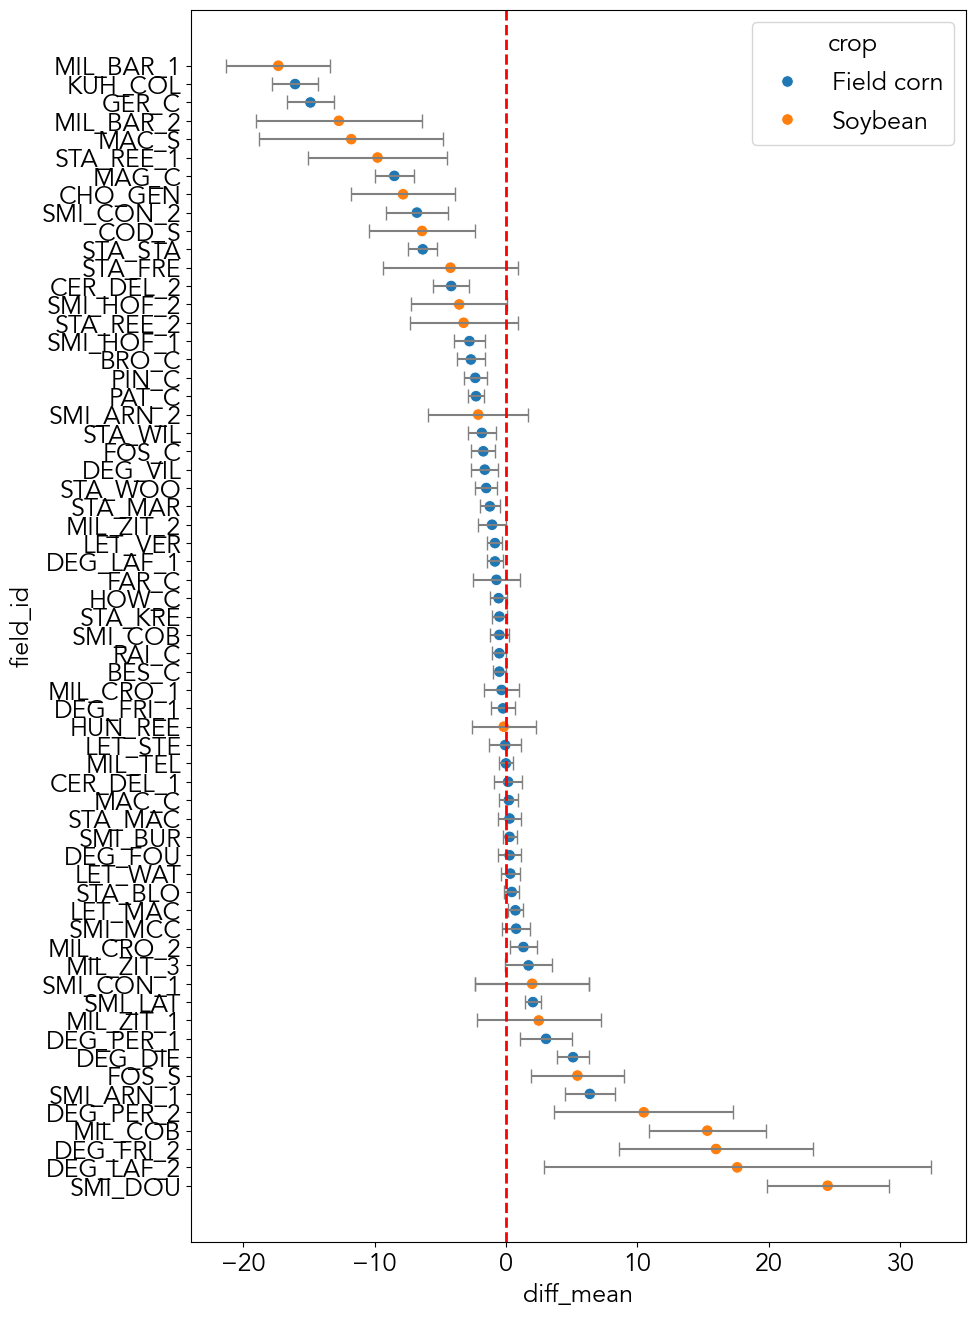

In [216]:
plt.figure(figsize=(10, 16))

plt.errorbar(diff_df['diff_mean'], diff_df['field_id'], xerr=diff_df['se_diff'], fmt="None", capsize=5, ecolor='grey')
sns.scatterplot(data=diff_df, x="diff_mean", y="field_id", hue='crop',s=70, hue_order=['Field corn', 'Soybean'])
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


In [376]:
biomass_2025 = pd.read_csv('Data/2025/fresh_biomass_2025.csv')
biomass_2025 = clean_columns(biomass_2025)
biomass_2025['treatment'] = biomass_2025['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})
biomass_2025 = biomass_2025.loc[(biomass_2025['crop'] == 'Field corn') | (biomass_2025['crop'] == 'Soybean')]

biomass_ny_2025 = biomass_2025.loc[biomass_2025['state'] == 'New York']

biomass_2025

,data_collector,state,field_id,date,sampling_period,crop,treatment,section_number,plant_growth_stage,number_of_plants,total_weight_g,notes,untared_weight_g
0,Chloe Yi-Luo Cho,New York,CHO_GEN,6/27/25,V3/V4,Soybean,Neonicotinoid,1,V3,15,79.7,NaN,NaN
1,Chloe Yi-Luo Cho,New York,CHO_GEN,6/27/25,V3/V4,Soybean,Neonicotinoid,2,V3,15,73.8,NaN,NaN
2,Chloe Yi-Luo Cho,New York,CHO_GEN,6/27/25,V3/V4,Soybean,Neonicotinoid,3,V3,15,73.4,NaN,NaN
3,Chloe Yi-Luo Cho,New York,CHO_GEN,6/27/25,V3/V4,Soybean,Neonicotinoid,4,V3,15,78.6,NaN,NaN
4,Chloe Yi-Luo Cho,New York,CHO_GEN,6/27/25,V3/V4,Soybean,Neonicotinoid,5,V3,15,97.7,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1219,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,5,V3/V4,15,2.5,NaN,NaN
1220,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,6,V3/V4,15,81.0,NaN,NaN
1221,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,7,V3/V4,15,110.5,NaN,NaN
1222,DAB,Vermont,FOS_S,7/28/25,V3/V4,Soybean,Neonicotinoid,8,V3/V4,15,109.3,NaN,NaN


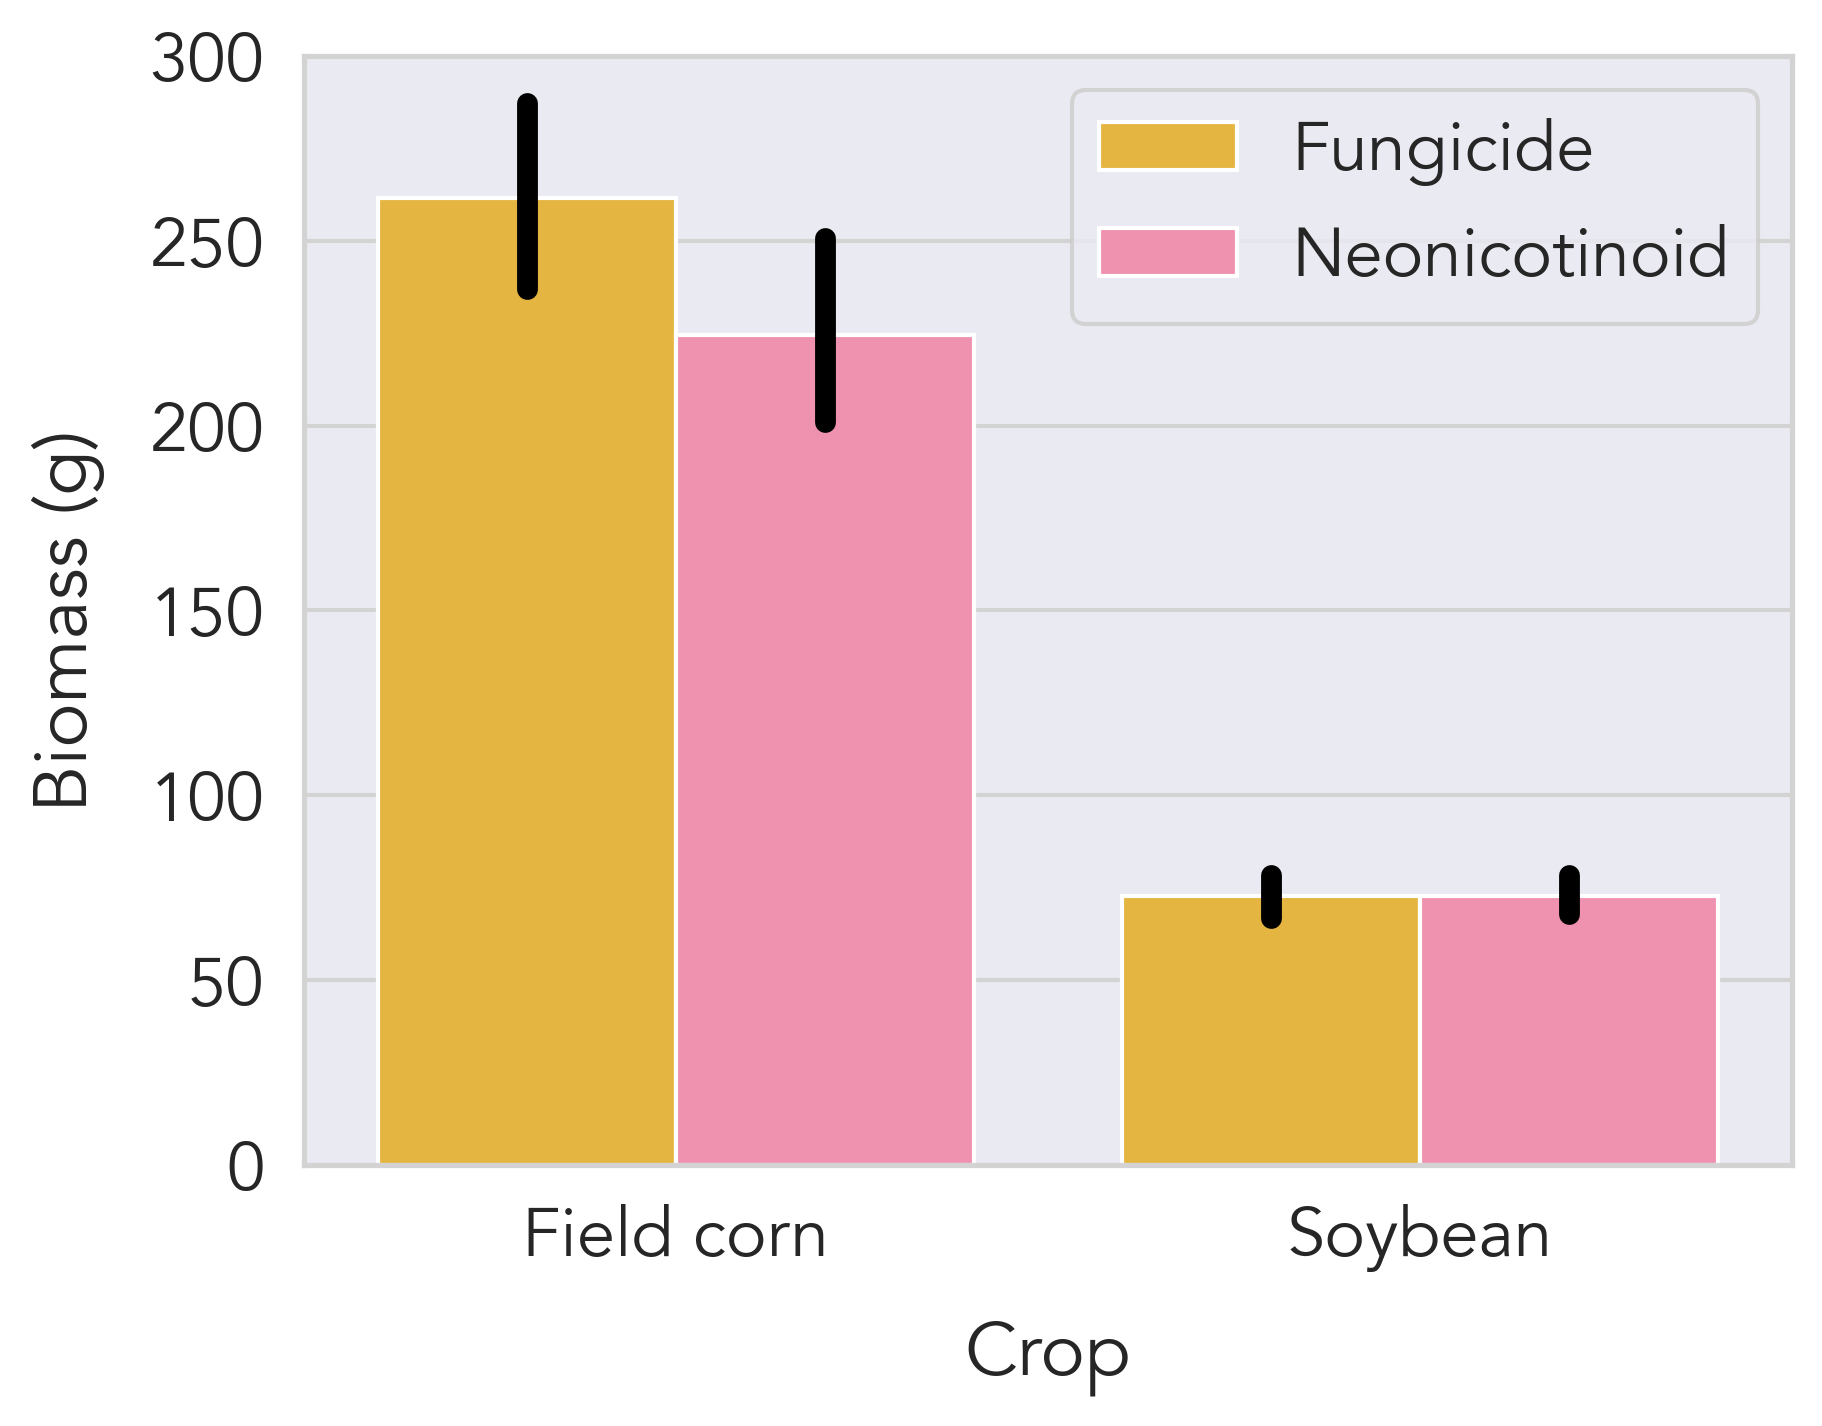

In [432]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

sns.barplot(
    data=biomass_ny_2025,
    x="crop",
    order=['Field corn', 'Soybean'],
    y="total_weight_g",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)
plt.legend(loc='upper right')

plt.xlabel("Crop", labelpad=10)
plt.ylabel("Biomass (g) ", labelpad=10)
plt.ylim(0, 300)
plt.show()


In [385]:
t1 = biomass_ny_2025.loc[(biomass_ny_2025['treatment'] == 'Neonicotinoid') & (biomass_ny_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_ny_2025.loc[(biomass_ny_2025['treatment'] == 'Fungicide') & (biomass_ny_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.3768358437898853, pvalue=0.02381836779011994, df=31)

In [386]:
t1 = biomass_ny_2025.loc[(biomass_ny_2025['treatment'] == 'Neonicotinoid') & (biomass_ny_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_ny_2025.loc[(biomass_ny_2025['treatment'] == 'Fungicide') & (biomass_ny_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.0661498536254339, pvalue=0.948132140096479, df=15)

In [404]:
len(biomass_ny_2025.loc[biomass_ny_2025['crop'] == 'Field corn']['field_id'].unique())

32

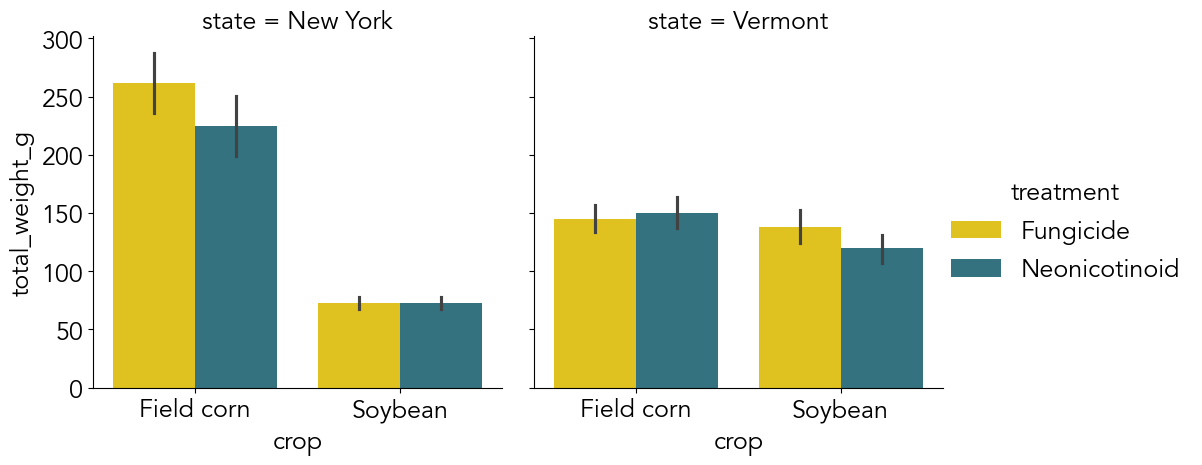

In [246]:
g = sns.catplot(
    data=biomass_2025, 
    kind="bar", 
    x="crop", 
    order=['Field corn', 'Soybean'],
    y="total_weight_g", 
    hue="treatment",  # First Hue (Colors)
    col="state",     # Second Hue (Subplots)
    palette=['#FFD700', "#287a8c"],
    hue_order=["Fungicide", "Neonicotinoid"],
)

In [248]:
t1 = biomass_2025.loc[(biomass_2025['state'] == 'New York') & (biomass_2025['treatment'] == 'Neonicotinoid') & (biomass_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2025.loc[(biomass_2025['state'] == 'New York') & (biomass_2025['treatment'] == 'Fungicide') & (biomass_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.3768358437898853, pvalue=0.02381836779011994, df=31)

In [249]:
t1 = biomass_2025.loc[(biomass_2025['state'] == 'New York') & (biomass_2025['treatment'] == 'Neonicotinoid') & (biomass_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2025.loc[(biomass_2025['state'] == 'New York') & (biomass_2025['treatment'] == 'Fungicide') & (biomass_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.0661498536254339, pvalue=0.948132140096479, df=15)

In [250]:
t1 = biomass_2025.loc[(biomass_2025['state'] == 'Vermont') & (biomass_2025['treatment'] == 'Neonicotinoid') & (biomass_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2025.loc[(biomass_2025['state'] == 'Vermont') & (biomass_2025['treatment'] == 'Fungicide') & (biomass_2025['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.3009976962063793, pvalue=0.7695816379877504, df=10)

In [251]:
t1 = biomass_2025.loc[(biomass_2025['state'] == 'Vermont') & (biomass_2025['treatment'] == 'Neonicotinoid') & (biomass_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2025.loc[(biomass_2025['state'] == 'Vermont') & (biomass_2025['treatment'] == 'Fungicide') & (biomass_2025['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.059824363530467, pvalue=0.17560030571447874, df=2)

In [211]:
grouped = biomass_2025.groupby(['field_id', 'treatment'])['total_weight_g'].agg(mean='mean', sem='sem').reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values=['mean', 'sem'])

diff_df = pd.DataFrame()
diff_df['diff_mean'] = grouped['mean']['Neonicotinoid'] - grouped['mean']['Fungicide']

se_neonic = grouped['sem']['Neonicotinoid']
se_fung = grouped['sem']['Fungicide']
diff_df['se_diff'] = np.sqrt(se_neonic**2 + se_fung**2)

diff_df = diff_df.reset_index()
diff_df = diff_df.sort_values('diff_mean')
diff_df = pd.merge(diff_df, biomass_2025[['field_id', 'crop']], on='field_id', how='left').drop_duplicates()

diff_df.head()

,field_id,diff_mean,se_diff,crop
0,SMI_CON_2,-411.433333,93.509540,Field corn
18,MIL_CRO_2,-143.777778,39.415208,Field corn
36,STA_STA,-136.000000,15.991221,Field corn
54,CER_DEL_2,-134.444444,38.776982,Field corn
72,DEG_LAF_1,-106.888889,123.172768,Field corn


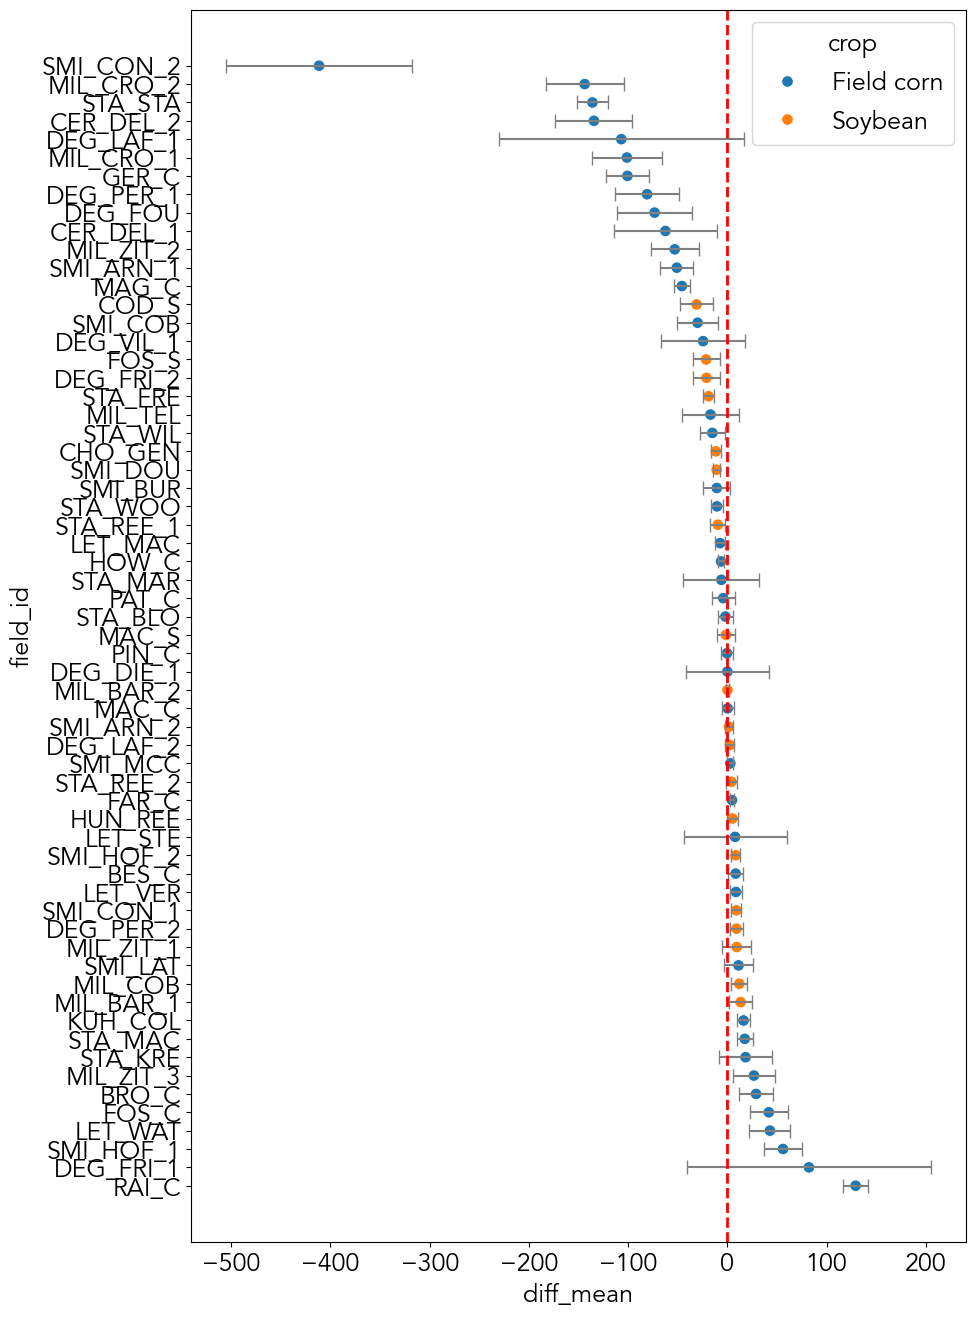

In [212]:
plt.figure(figsize=(10, 16))

plt.errorbar(diff_df['diff_mean'], diff_df['field_id'], xerr=diff_df['se_diff'], fmt="None", capsize=5, ecolor='grey')
sns.scatterplot(data=diff_df, x="diff_mean", y="field_id", hue='crop', s=70)
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


In [387]:
grain_2025 = pd.read_csv('Data/2025/grain_yield_2025.csv')
grain_2025 = clean_columns(grain_2025)
grain_2025['treatment'] = grain_2025['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})

grain_ny_2025 = grain_2025.loc[grain_2025['state'] == 'New York']

grain_2025.head()

,data_collector,state,field_id,date,sampling_period,crop,grain_or_silage,treatment,yield_bu_acre
0,Paul Cerosaletti,New York,CER_DEL_1,12/8/25,Harvest,Field corn,Grain,Neonicotinoid,186.41
1,Paul Cerosaletti,New York,CER_DEL_1,12/8/25,Harvest,Field corn,Grain,Fungicide,182.19
2,Paul Cerosaletti,New York,CER_DEL_2,12/8/25,Harvest,Field corn,Grain,Neonicotinoid,188.93
3,Paul Cerosaletti,New York,CER_DEL_2,12/8/25,Harvest,Field corn,Grain,Fungicide,200.62
4,Janice Degni,New York,DEG_FRI_1,11/4/25,Harvest,Field corn,Grain,Neonicotinoid,87.07


In [399]:
len(grain_ny_2025['field_id'].unique())

24

/var/folders/vt/gz9c8wh17772k93xq1vtnl0c0000gn/T/ipykernel_56400/1867547925.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


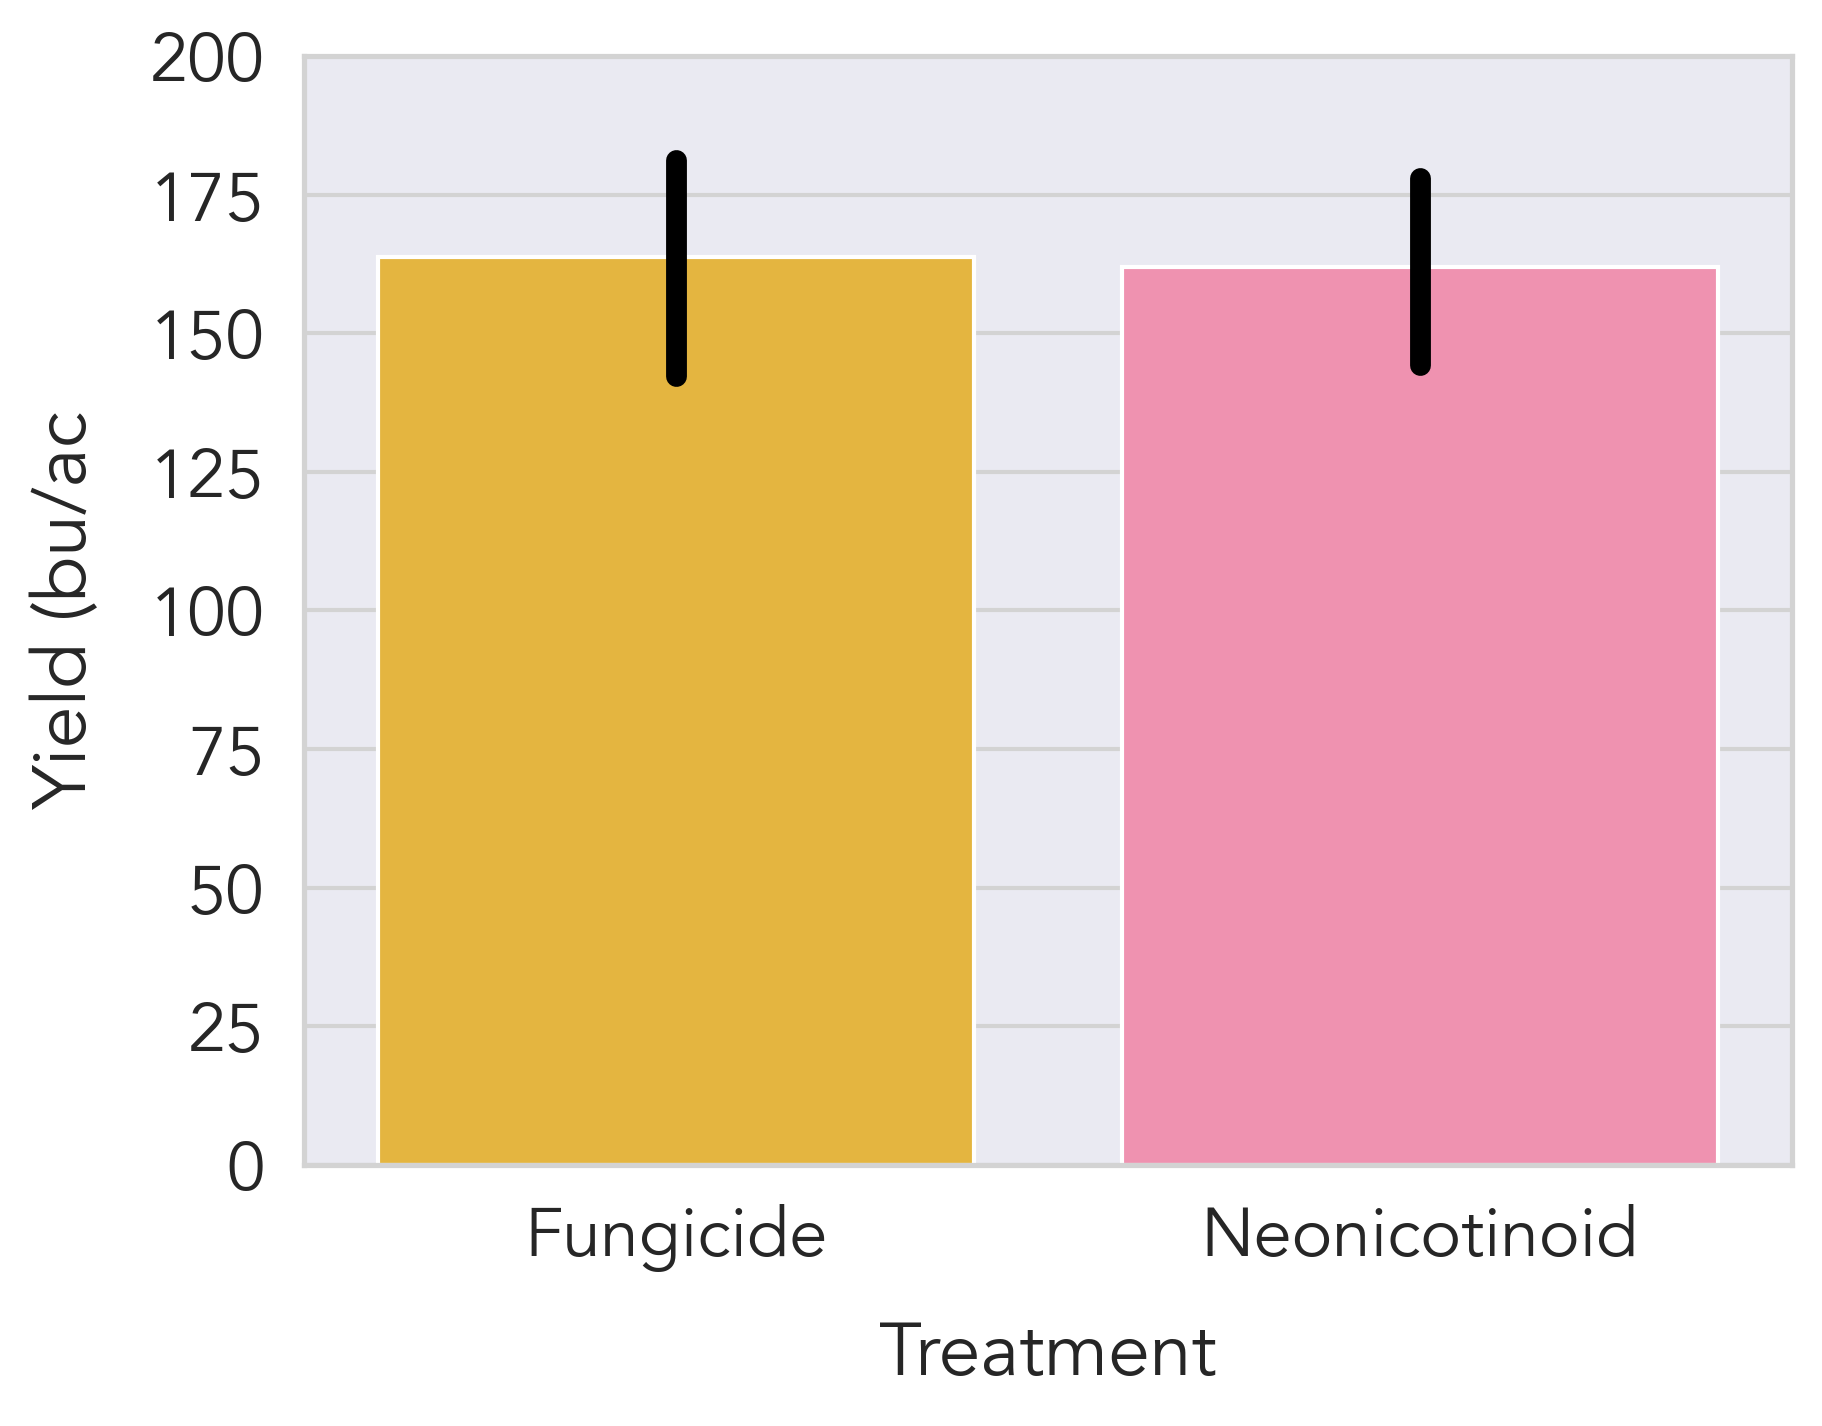

In [431]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

sns.barplot(
    data=grain_ny_2025,
    x="treatment",
    y="yield_bu_acre",
    palette=['#FFC125', '#FF82AB'],
    order=["Fungicide", "Neonicotinoid"],
    err_kws={'linewidth': 5, 'color':'black'}
)

plt.ylabel("Yield (bu/ac", labelpad=10)
plt.xlabel("Treatment", labelpad=10)
plt.ylim(0, 200)
plt.show()


In [268]:
t1 = grain_2025.loc[(grain_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_bu_acre'].mean()
t2 = grain_2025.loc[(grain_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_bu_acre'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-0.7178852559330153, pvalue=0.47975831052869156, df=24)

In [108]:
grouped = grain_2025.groupby(['field_id', 'treatment'])['yield_bu_acre'].mean().reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values='yield_bu_acre')
grouped = grouped.reset_index().rename_axis(None, axis=1)
grouped['Difference'] = grouped['Neonicotinoid'] - grouped['Fungicide']
grouped = grouped.sort_values('Difference')

grouped


,field_id,Fungicide,Neonicotinoid,Difference
23,STA_WIL,229.9200,178.2600,-51.6600
14,SMI_ARN_1,173.8300,135.3700,-38.4600
4,FAR_C,227.8100,202.0900,-25.7200
9,HUN_TER,210.4500,191.8400,-18.6100
1,CER_DEL_2,200.6200,188.9300,-11.6900
13,MIL_ZIT_3,134.8000,124.0000,-10.8000
5,HUN_EDE_2,218.0000,207.4000,-10.6000
17,SMI_HOF_1,85.0000,76.0000,-9.0000
7,HUN_HUR,194.4000,187.7000,-6.7000
18,SMI_MCC,173.4200,168.7600,-4.6600


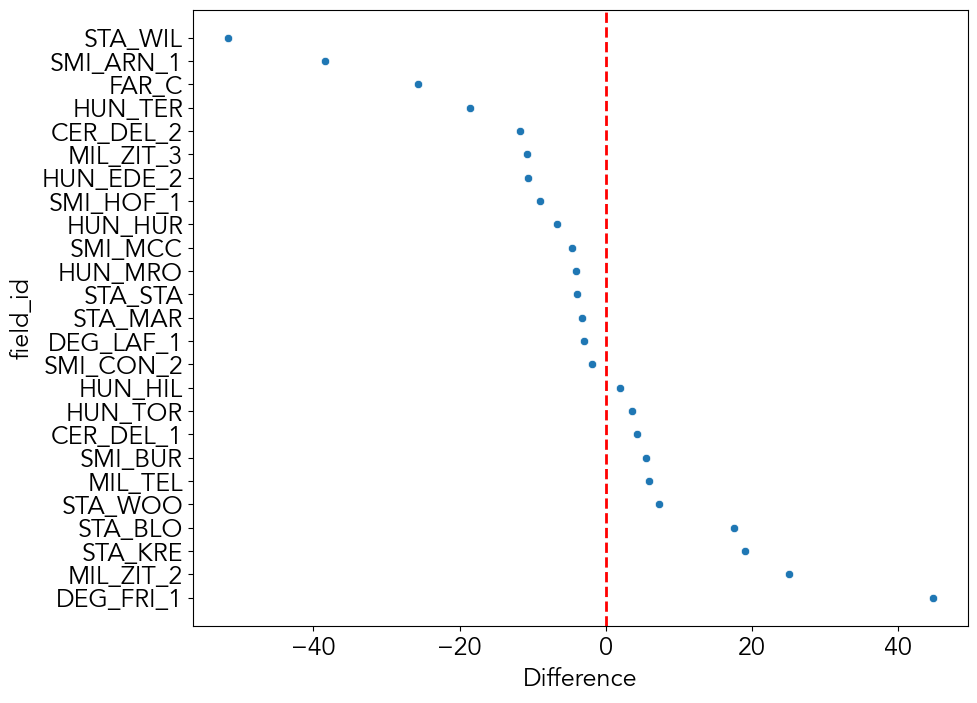

In [109]:
plt.figure(figsize=(10, 8))

sns.scatterplot(data=grouped, x="Difference", y="field_id")
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


In [405]:
silage_2025 = pd.read_csv('Data/2025/silage_yield_2025.csv')
silage_2025 = clean_columns(silage_2025)
silage_2025['treatment'] = silage_2025['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})

silage_ny_2025 = silage_2025.loc[silage_2025['state'] == 'New York']

silage_2025.head()

,data_collector,state,field_id,date,sampling_period,crop,grain_or_silage,treatment,yield_tons_acre,yield_dry_matter,notes
0,DAB,Vermont,BES_C,9/27/25,Harvest,Field corn,Silage,Fungicide,16.8,6.9,NaN
1,DAB,Vermont,BES_C,9/27/25,Harvest,Field corn,Silage,Neonicotinoid,18.4,7.5,NaN
2,DAB,Vermont,BRO_C,9/17/25,Harvest,Field corn,Silage,Fungicide,26.5,8.5,NaN
3,DAB,Vermont,BRO_C,9/17/25,Harvest,Field corn,Silage,Neonicotinoid,16.4,5.6,NaN
4,DAB,Vermont,FOS_C,10/6/25,Harvest,Field corn,Silage,Fungicide,21.6,9.1,NaN


/var/folders/vt/gz9c8wh17772k93xq1vtnl0c0000gn/T/ipykernel_56400/404731897.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


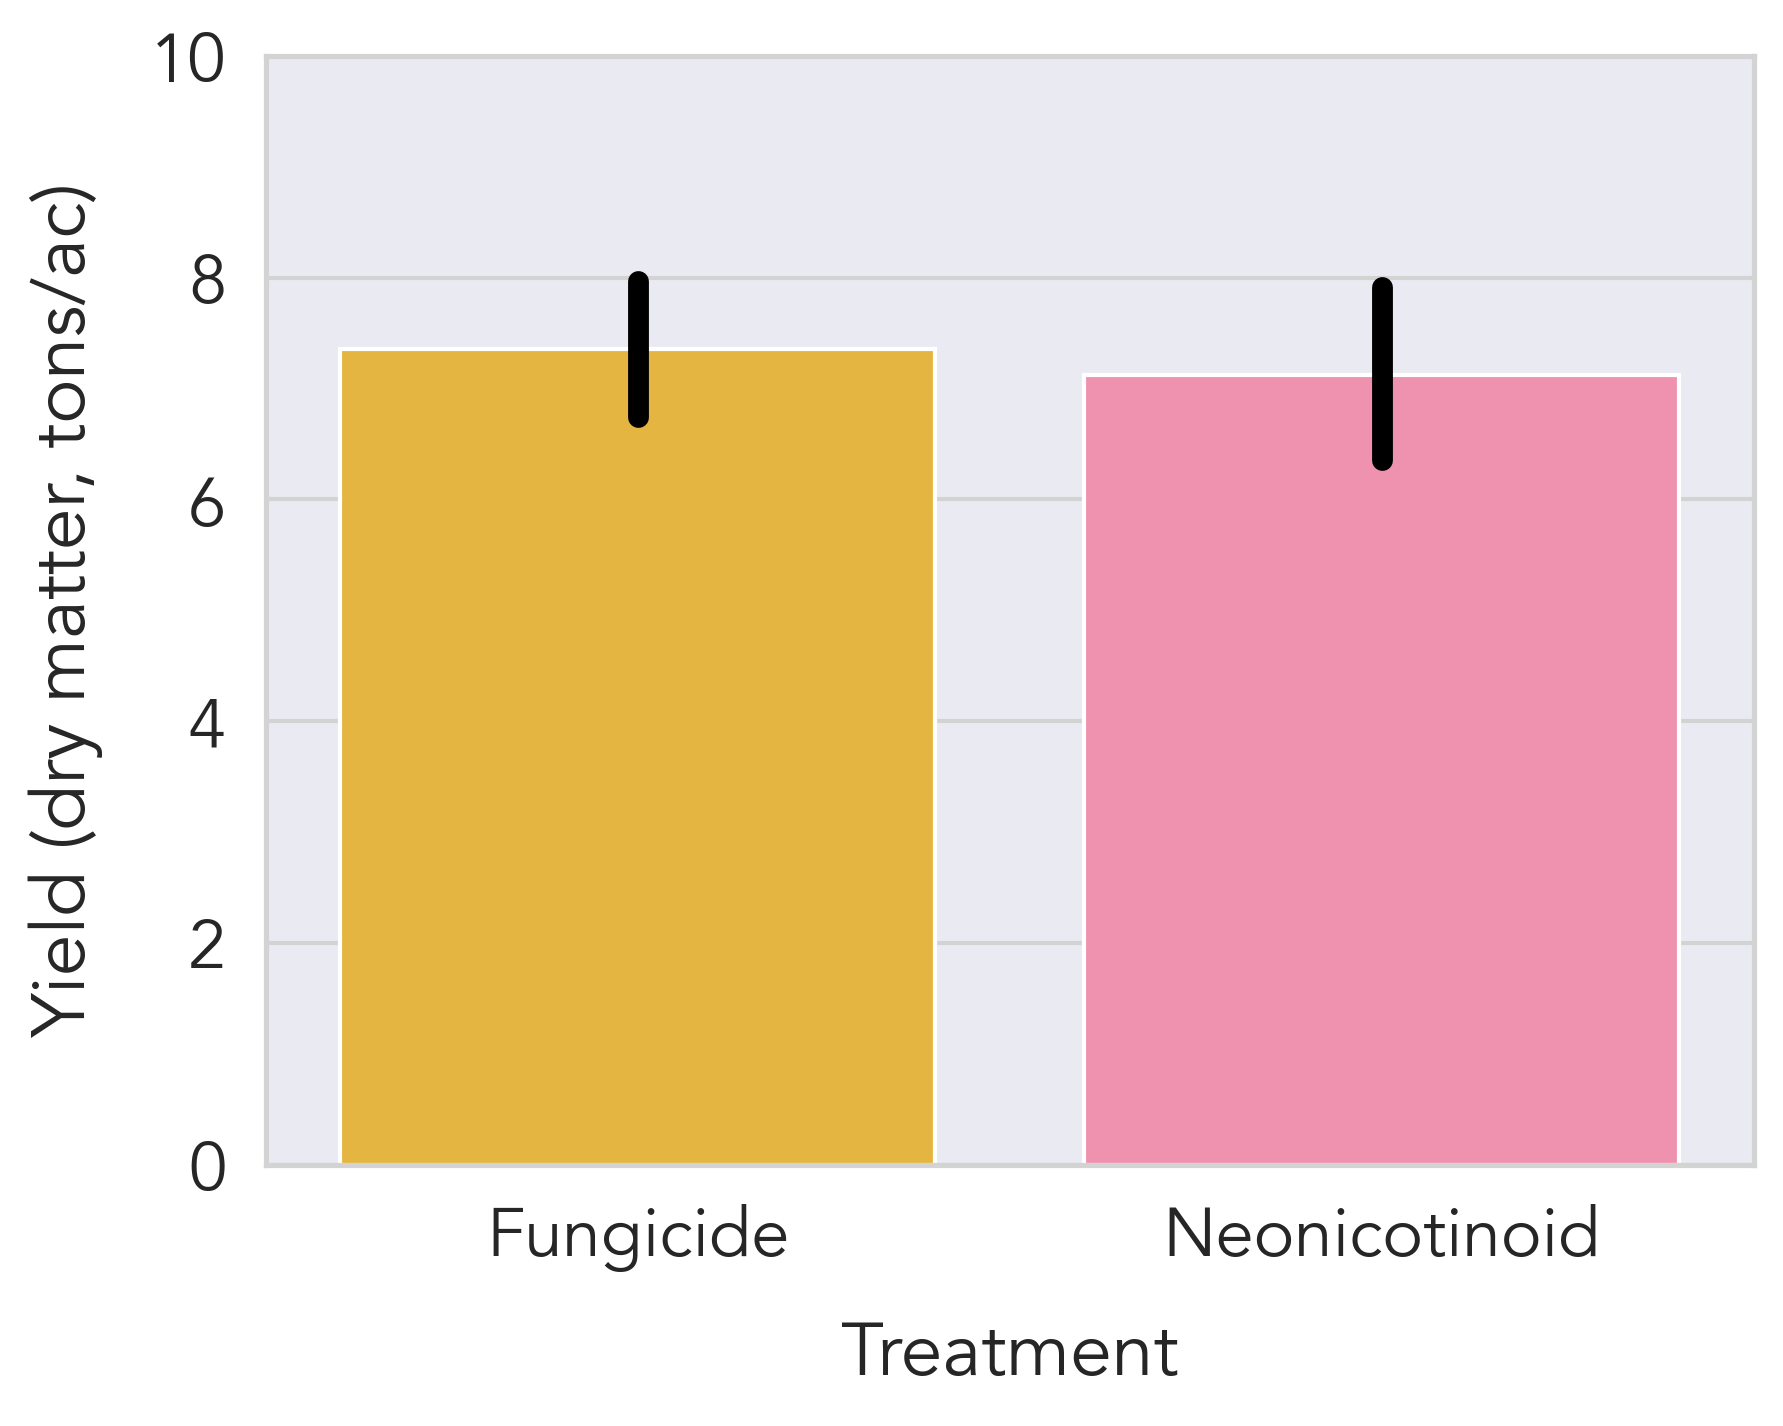

In [430]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

sns.barplot(
    data=silage_ny_2025,
    x="treatment",
    y="yield_dry_matter",
    palette=['#FFC125', '#FF82AB'],
    order=["Fungicide", "Neonicotinoid"],
    err_kws={'linewidth': 5, 'color':'black'}
)

plt.xlabel("Treatment", labelpad=10)
plt.ylabel("Yield (dry matter, tons/ac)", labelpad=10)
plt.ylim(0, 10)
plt.show()


In [413]:
len(silage_ny_2025['field_id'].unique())

16

In [267]:
t1 = silage_2025.loc[(silage_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_dry_matter'].mean().dropna()
t2 = silage_2025.loc[(silage_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_dry_matter'].mean().dropna()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.7921987485878743, pvalue=0.010353882336487976, df=23)

In [ ]:
t1 = silage_2025.loc[(silage_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_dry_matter'].mean().dropna()
t2 = silage_2025.loc[(silage_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_dry_matter'].mean().dropna()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-2.7921987485878743, pvalue=0.010353882336487976, df=23)

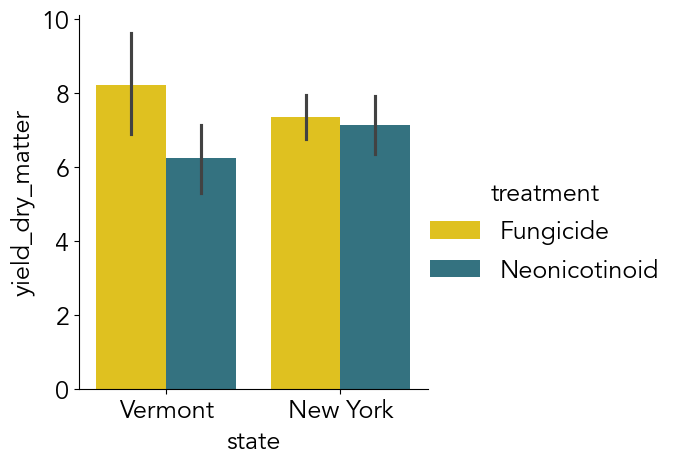

In [271]:
g = sns.catplot(
    data=silage_2025, 
    kind="bar", 
    x="state", 
    hue_order=["Fungicide", "Neonicotinoid"],
    y="yield_dry_matter", 
    hue="treatment",  # First Hue (Colors)
    palette=['#FFD700', "#287a8c"],
)

In [273]:
t1 = silage_2025.loc[(silage_2025['state'] == 'New York') & (silage_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_dry_matter'].mean().dropna()
t2 = silage_2025.loc[(silage_2025['state'] == 'New York') & (silage_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_dry_matter'].mean().dropna()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-0.9028050186080208, pvalue=0.3830529449350125, df=13)

In [274]:
t1 = silage_2025.loc[(silage_2025['state'] == 'Vermont') & (silage_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_dry_matter'].mean()
t2 = silage_2025.loc[(silage_2025['state'] == 'Vermont') & (silage_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_dry_matter'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-3.155378765457785, pvalue=0.011636401617764414, df=9)

In [256]:
grouped = silage_2025.groupby(['field_id', 'treatment'])['yield_dry_matter'].mean().reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values='yield_dry_matter')
grouped = grouped.reset_index().rename_axis(None, axis=1)
grouped['Difference'] = grouped['Neonicotinoid'] - grouped['Fungicide']
grouped = grouped.sort_values('Difference')


grouped.head()

,field_id,Fungicide,Neonicotinoid,Difference
17,MAG_C,12.70,6.20,-6.50
1,BRO_C,8.50,5.60,-2.90
6,FOS_C,9.10,6.30,-2.80
20,PAT_C,8.80,6.40,-2.40
12,LET_MAC,7.71,5.39,-2.32


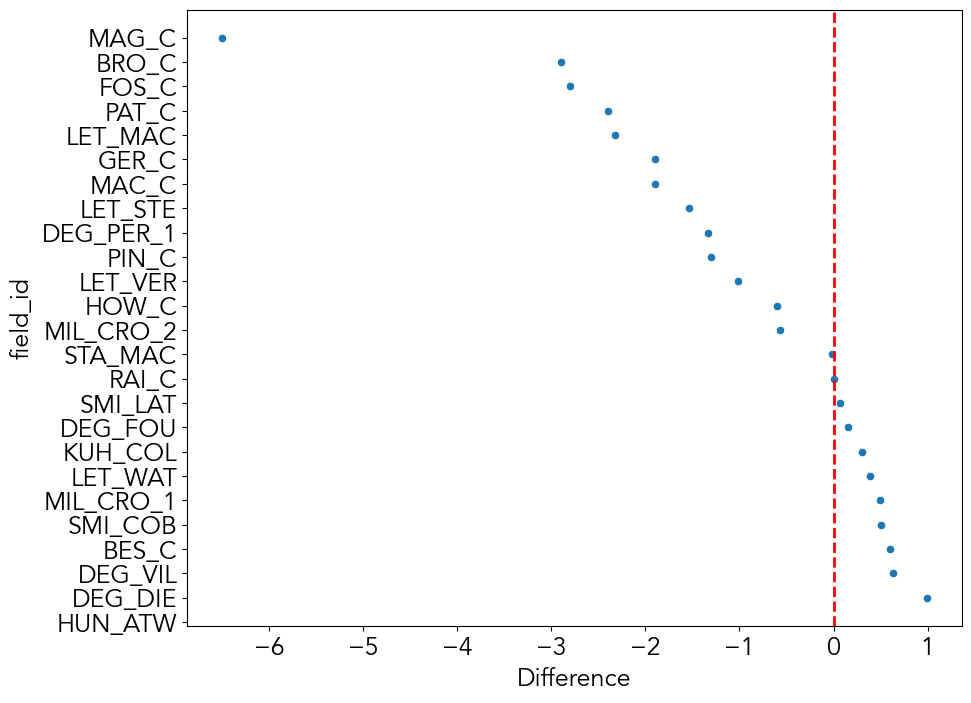

In [257]:
plt.figure(figsize=(10, 8))

sns.scatterplot(data=grouped, x="Difference", y="field_id")
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


In [414]:
soybean_2025 = pd.read_csv('Data/2025/soybean_yield_2025.csv')
soybean_2025 = clean_columns(soybean_2025)
soybean_2025['treatment'] = soybean_2025['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})

soybean_ny_2025 = soybean_2025.loc[soybean_2025['state'] == 'New York']

soybean_2025.head()

,data_collector,state,field_id,date,sampling_period,crop,treatment,yield_bu_acre
0,Chloe Cho,New York,CHO_GEN,10/27/25,Harvest,Soybean,Neonicotinoid,47.71
1,Chloe Cho,New York,CHO_GEN,10/27/25,Harvest,Soybean,Fungicide,49.64
2,Janice Degni,New York,DEG_FRI_2,11/4/25,Harvest,Soybean,Neonicotinoid,10.70
3,Janice Degni,New York,DEG_FRI_2,11/4/25,Harvest,Soybean,Fungicide,15.19
4,Janice Degni,New York,DEG_LAF_2,10/15/25,Harvest,Soybean,Neonicotinoid,50.99


/var/folders/vt/gz9c8wh17772k93xq1vtnl0c0000gn/T/ipykernel_56400/1449351740.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


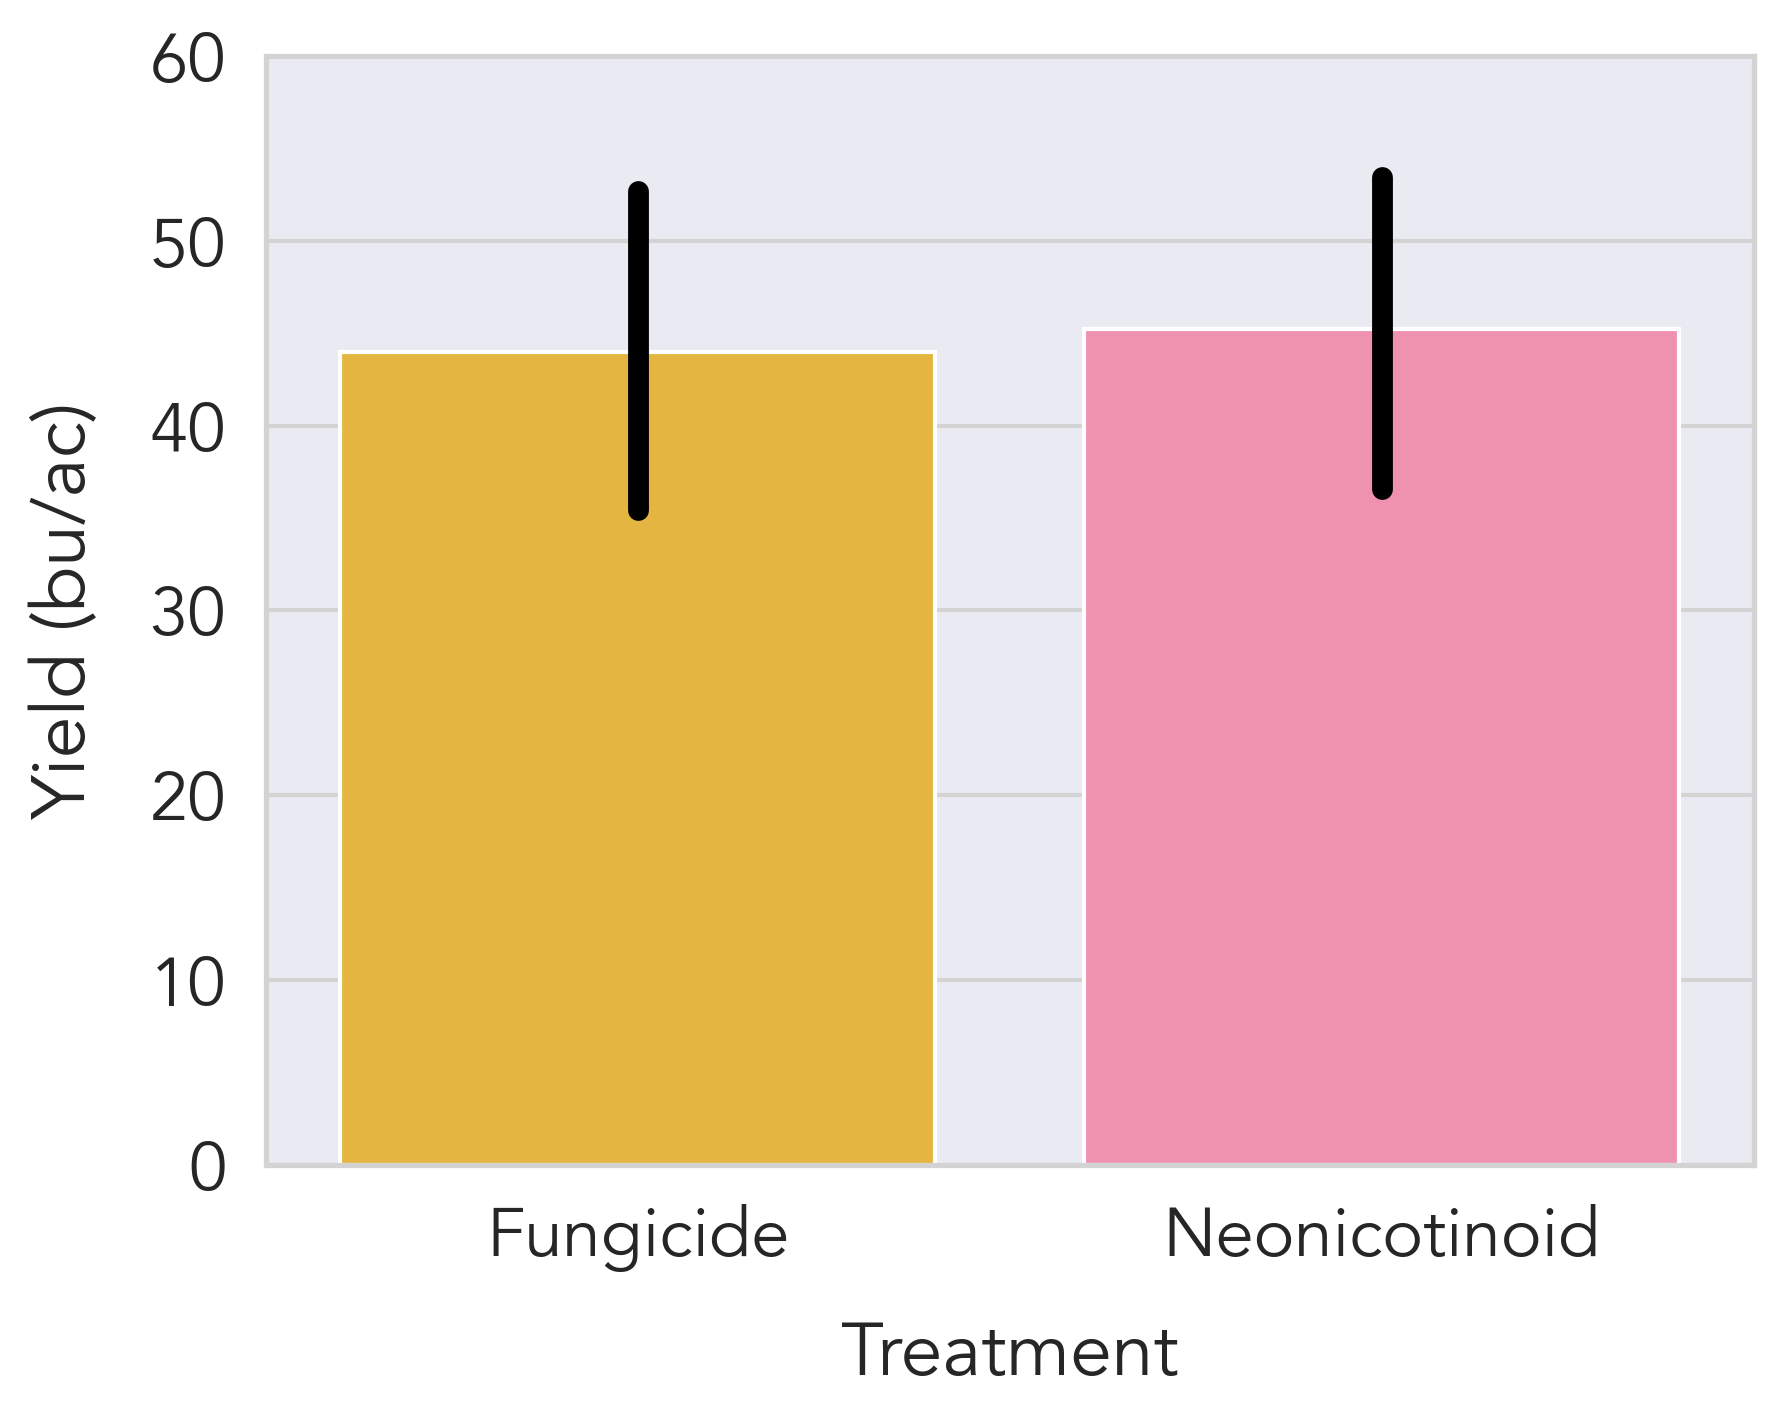

In [429]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

sns.barplot(
    data=soybean_ny_2025,
    x="treatment",
    y="yield_bu_acre",
    palette=['#FFC125', '#FF82AB'],
    order=["Fungicide", "Neonicotinoid"],
    err_kws={'linewidth': 5, 'color':'black'}
)

plt.xlabel("Treatment", labelpad=10)
plt.ylabel("Yield (bu/ac)", labelpad=10)
plt.ylim(0, 60)
plt.show()


In [419]:
len(soybean_ny_2025['field_id'].unique())

15

In [278]:
t1 = soybean_2025.loc[(soybean_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_bu_acre'].mean()
t2 = soybean_2025.loc[(soybean_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_bu_acre'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.9211245361404077, pvalue=0.3698731481973617, df=17)

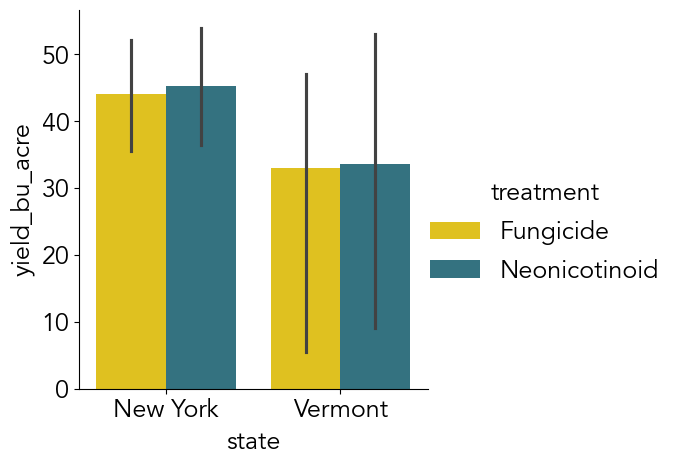

In [279]:
g = sns.catplot(
    data=soybean_2025, 
    kind="bar", 
    x="state", 
    hue_order=["Fungicide", "Neonicotinoid"],
    y="yield_bu_acre", 
    hue="treatment",  # First Hue (Colors)
    palette=['#FFD700', "#287a8c"],
)

In [280]:
t1 = soybean_2025.loc[(soybean_2025['state'] == 'New York') & (soybean_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_bu_acre'].mean().dropna()
t2 = soybean_2025.loc[(soybean_2025['state'] == 'New York') & (soybean_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_bu_acre'].mean().dropna()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.9630566888967412, pvalue=0.3518596859049695, df=14)

In [281]:
t1 = soybean_2025.loc[(soybean_2025['state'] == 'Vermont') & (soybean_2025['treatment'] == 'Neonicotinoid')].groupby('field_id')['yield_bu_acre'].mean()
t2 = soybean_2025.loc[(soybean_2025['state'] == 'Vermont') & (soybean_2025['treatment'] == 'Fungicide')].groupby('field_id')['yield_bu_acre'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.13210085934174004, pvalue=0.9069954524813534, df=2)

In [115]:
grouped = soybean_2025.groupby(['field_id', 'treatment'])['yield_bu_acre'].mean().reset_index()
grouped = grouped.pivot(index='field_id', columns='treatment', values='yield_bu_acre')
grouped = grouped.reset_index().rename_axis(None, axis=1)
grouped['Difference'] = grouped['Neonicotinoid'] - grouped['Fungicide']
grouped = grouped.sort_values('Difference')


grouped.head()

,field_id,Fungicide,Neonicotinoid,Difference
17,STA_REE_2,57.79,48.43,-9.36
1,COD_S,46.60,38.70,-7.90
15,STA_FRE,40.26,35.70,-4.56
2,DEG_FRI_2,15.19,10.70,-4.49
0,CHO_GEN,49.64,47.71,-1.93


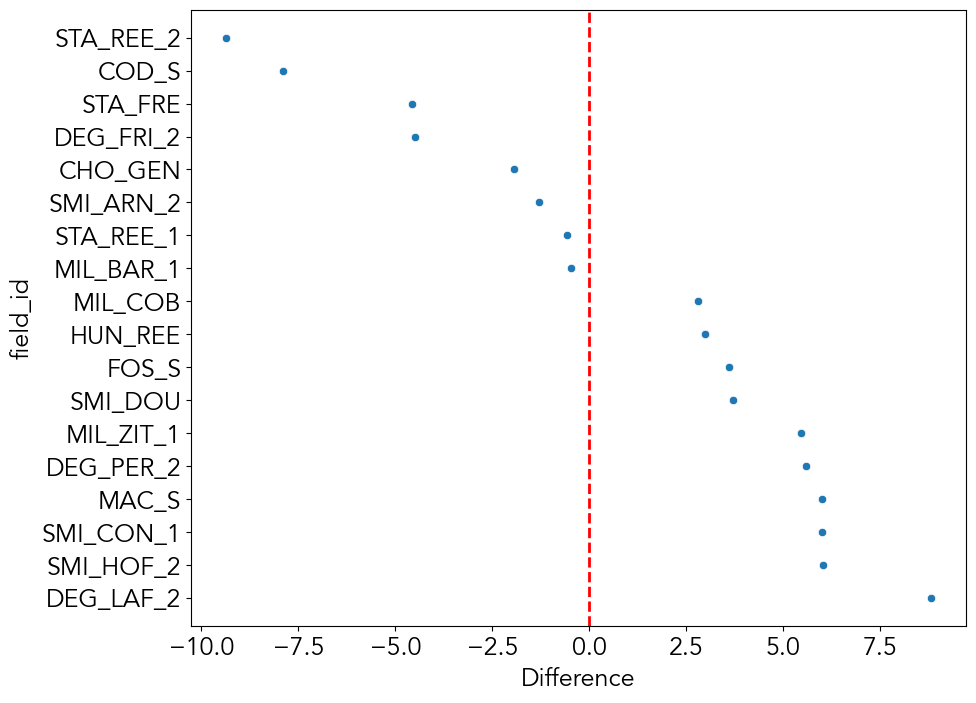

In [116]:
plt.figure(figsize=(10, 8))

sns.scatterplot(data=grouped, x="Difference", y="field_id")
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)


# 2026

In [348]:
deli_cup_26 = pd.read_csv('Data/2026/deli_cup_2026.csv')
deli_cup_26 = clean_columns(deli_cup_26)
deli_cup_26['scm_total'] = deli_cup_26['scm_larvae_sum'] + deli_cup_26['scm_pupae_sum']
deli_cup_26['scm_per_seed'] = deli_cup_26['scm_total'] / deli_cup_26['number_seeds']
deli_cup_26['prop_seeds'] = deli_cup_26['scm_seed'] / deli_cup_26['number_seeds']
deli_cup_26['treatment'] = deli_cup_26['treatment'].replace({'F': 'Fungicide', 'N': 'Neonicotinoid', 'D': 'Diamide'})
deli_cup_26['seed_type'] = deli_cup_26['seed_type'].replace({'Field Corn': 'Field corn', 'Soy': 'Soybean', 'Sweet Corn': 'Sweet corn', 'Snap': 'Snap bean'})
deli_cup_26 = deli_cup_26.loc[(deli_cup_26['seed_type'] == 'Field corn') | (deli_cup_26['seed_type'] == 'Soybean')]

deli_cup_26

,sample_id,project_r_l_c,field_id,treatment,collection_date,seed_type,number_seeds,scm_larvae_sum,scm_pupae_sum,scm_seed,...,wireworms,other_seeds,wireworm_presence_absence,grub_presence_absence,checked,ordered_entered,notes,scm_total,scm_per_seed,prop_seeds
0,26_D_2981,R,CER_DEL_1,Fungicide,6/23/26,Soybean,15,1,0,0,...,0,1,No,No,Yes,858,NaN,1,0.066667,0.000000
1,26_D_2986,R,CER_DEL_1,Fungicide,6/23/26,Soybean,15,1,0,0,...,0,0,No,No,Yes,859,NaN,1,0.066667,0.000000
2,26_D_2985,R,CER_DEL_1,Fungicide,6/23/26,Soybean,12,1,0,1,...,0,2,No,No,Yes,860,NaN,1,0.083333,0.083333
3,26_D_2980,R,CER_DEL_1,Fungicide,6/23/26,Soybean,15,3,0,0,...,0,2,No,No,Yes,1645,NaN,3,0.200000,0.000000
4,26_D_2984,R,CER_DEL_1,Fungicide,6/23/26,Soybean,13,0,0,0,...,0,3,No,No,Yes,1646,NaN,0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1314,26_D_1136,R,STA_YUN,Neonicotinoid,5/11/26,Soybean,15,0,0,0,...,0,4,No,No,Yes,393,NaN,0,0.000000,0.000000
1315,26_D_1137,R,STA_YUN,Neonicotinoid,5/11/26,Soybean,14,0,0,0,...,0,2,No,No,Yes,394,NaN,0,0.000000,0.000000
1316,26_D_1134,R,STA_YUN,Neonicotinoid,5/11/26,Soybean,15,0,0,0,...,0,3,No,No,Yes,407,NaN,0,0.000000,0.000000
1317,26_D_1133,R,STA_YUN,Neonicotinoid,5/11/26,Soybean,15,0,0,0,...,0,1,No,No,Yes,408,NaN,0,0.000000,0.000000


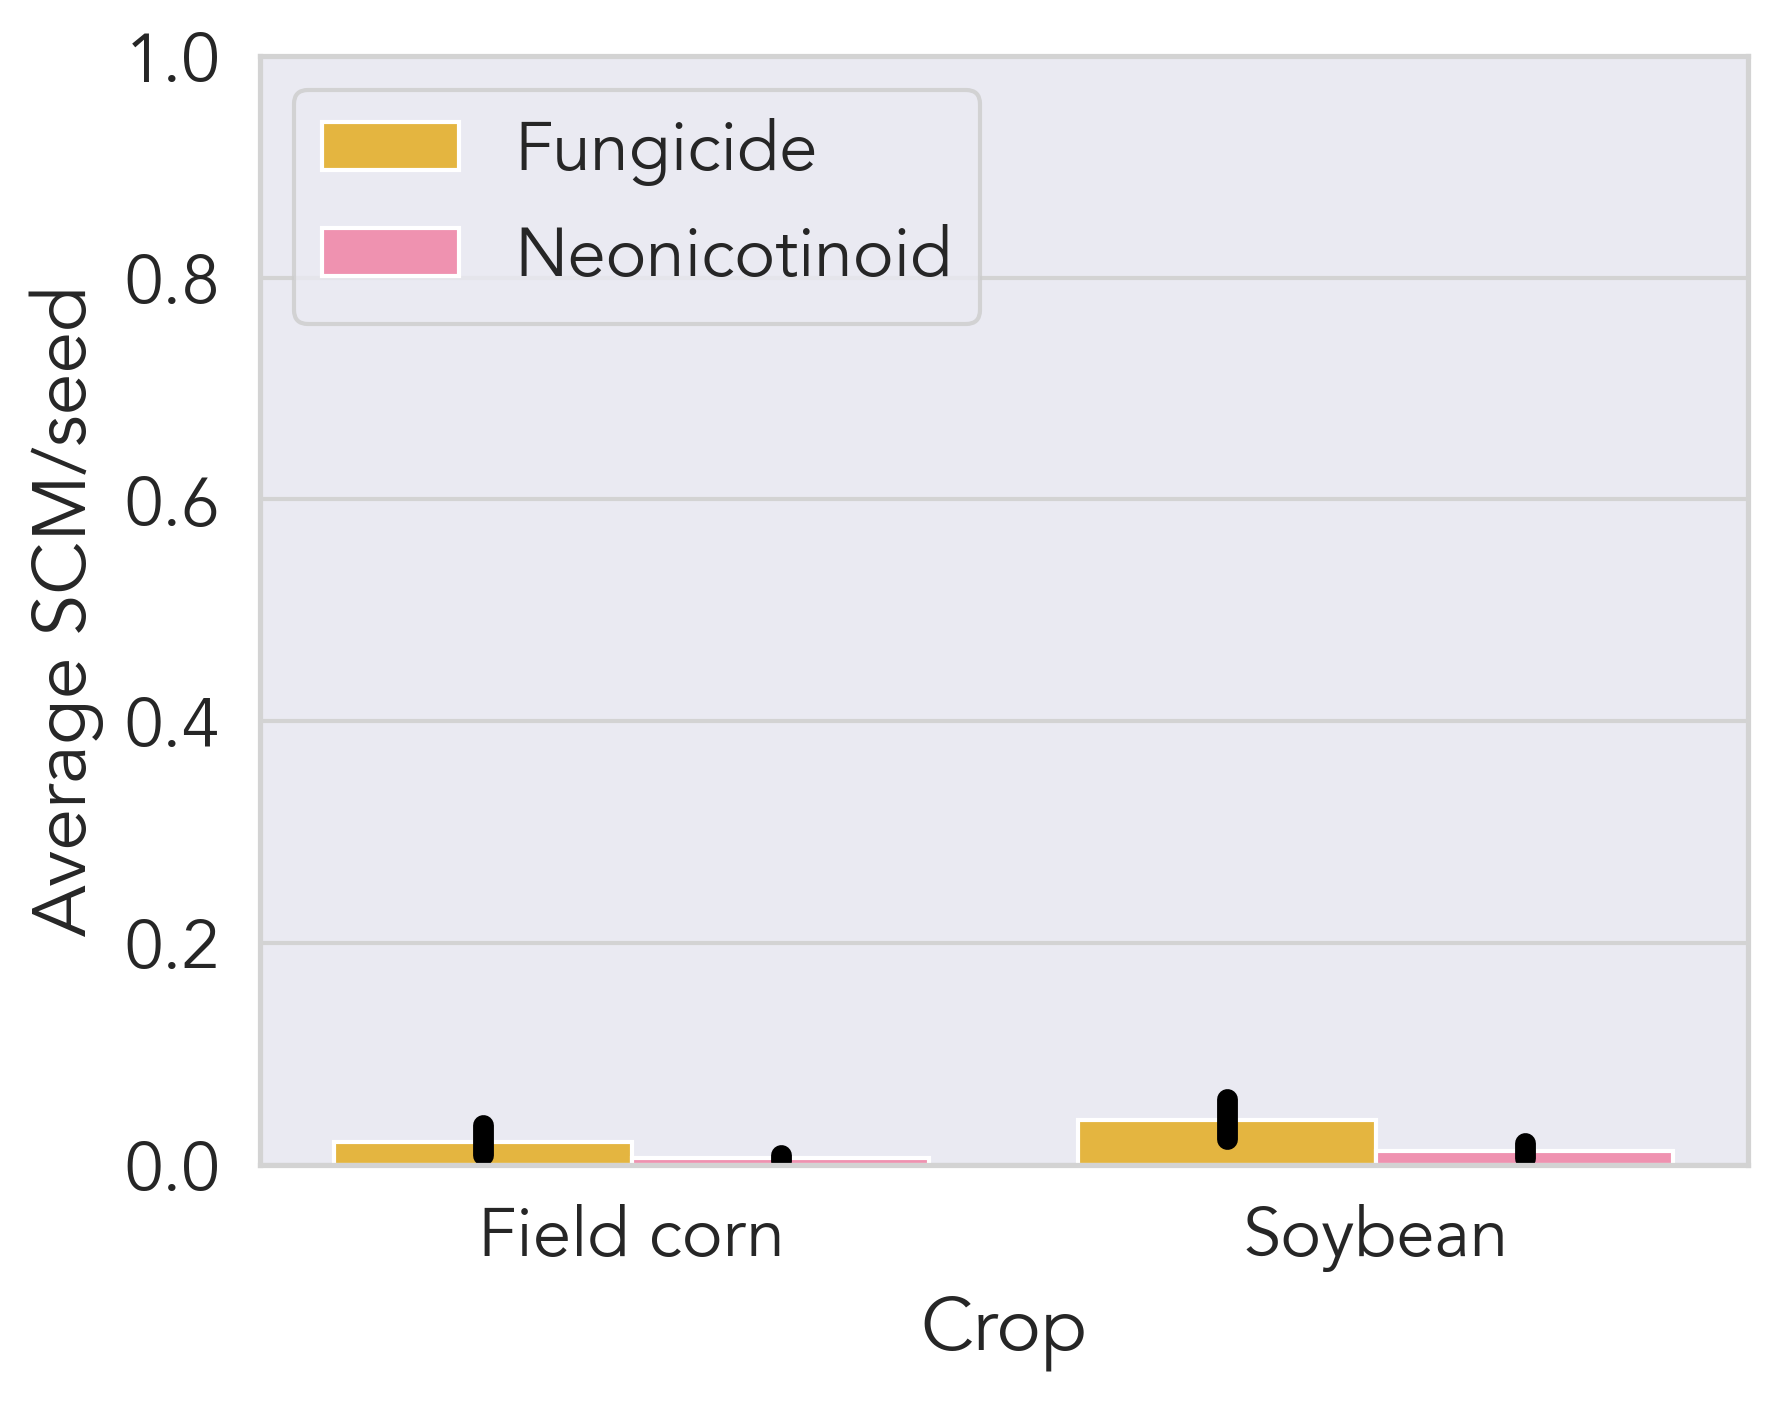

In [349]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

ax = sns.barplot(
    data=deli_cup_26,
    x="seed_type",
    order=['Field corn', 'Soybean'],
    y="scm_per_seed",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)

plt.ylabel('Average SCM/seed')
plt.xlabel('Crop')

plt.legend(loc='upper left')

plt.ylim(0, 1)
plt.show()


In [361]:
len(deli_cup_26.loc[deli_cup_26['seed_type'] == 'Field corn']['field_id'].unique())

42

In [350]:
deli_cup_26.groupby('treatment')['scm_per_seed'].mean()

treatment
Diamide          0.009530
Fungicide        0.026553
Neonicotinoid    0.007893
Name: scm_per_seed, dtype: float64

In [355]:
deli_cup_26.groupby('seed_type')['scm_per_seed'].agg('mean')

seed_type
Field corn    0.012489
Soybean       0.024948
Name: scm_per_seed, dtype: float64

In [352]:
t1 = deli_cup_26.loc[(deli_cup_26['treatment'] == 'Neonicotinoid') & (deli_cup_26['seed_type'] == 'Field corn')].groupby('field_id')['scm_per_seed'].mean()
t2 = deli_cup_26.loc[(deli_cup_26['treatment'] == 'Fungicide') & (deli_cup_26['seed_type'] == 'Field corn')].groupby('field_id')['scm_per_seed'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-1.130645687238578, pvalue=0.2647750079381682, df=41)

In [353]:
t1 = deli_cup_26.loc[(deli_cup_26['treatment'] == 'Neonicotinoid') & (deli_cup_26['seed_type'] == 'Soybean')].groupby('field_id')['scm_per_seed'].mean()
t2 = deli_cup_26.loc[(deli_cup_26['treatment'] == 'Fungicide') & (deli_cup_26['seed_type'] == 'Soybean')].groupby('field_id')['scm_per_seed'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-1.4030717633781744, pvalue=0.17761000868524976, df=18)

In [434]:
stand_2026 = pd.read_csv('Data/2026/stand_loss_2026.csv')
stand_2026 = clean_columns(stand_2026)

stand_2026['treatment'] = stand_2026['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})
stand_2026 = stand_2026.loc[(stand_2026['crop'] == 'Field corn') | (stand_2026['crop'] == 'Soybean')]

stand_2026

,data_collector,field_id,date,sampling_period,crop,treatment,section_number,plant_growth_stage,stand_count,notes,unnamed_10
0,Marylynn Collins,KUH_COL,5/27/2026,VE/V1,Field corn,Neonicotinoid,1,V1,22,NaN,NaN
1,Marylynn Collins,KUH_COL,5/27/2026,VE/V1,Field corn,Neonicotinoid,2,V1,21,NaN,NaN
2,Marylynn Collins,KUH_COL,5/27/2026,VE/V1,Field corn,Neonicotinoid,3,V1,21,NaN,NaN
3,Marylynn Collins,KUH_COL,5/27/2026,VE/V1,Field corn,Neonicotinoid,4,V1,17,NaN,NaN
4,Marylynn Collins,KUH_COL,5/27/2026,VE/V1,Field corn,Neonicotinoid,5,V1,20,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2380,Janice Degni,DEG_PER_2,6/16/2026,VE/V1,Field corn,Fungicide,5,NaN,24,NaN,NaN
2381,Janice Degni,DEG_PER_2,6/16/2026,VE/V1,Field corn,Fungicide,6,NaN,35,NaN,NaN
2382,Janice Degni,DEG_PER_2,6/16/2026,VE/V1,Field corn,Fungicide,7,NaN,29,NaN,NaN
2383,Janice Degni,DEG_PER_2,6/16/2026,VE/V1,Field corn,Fungicide,8,NaN,35,NaN,NaN


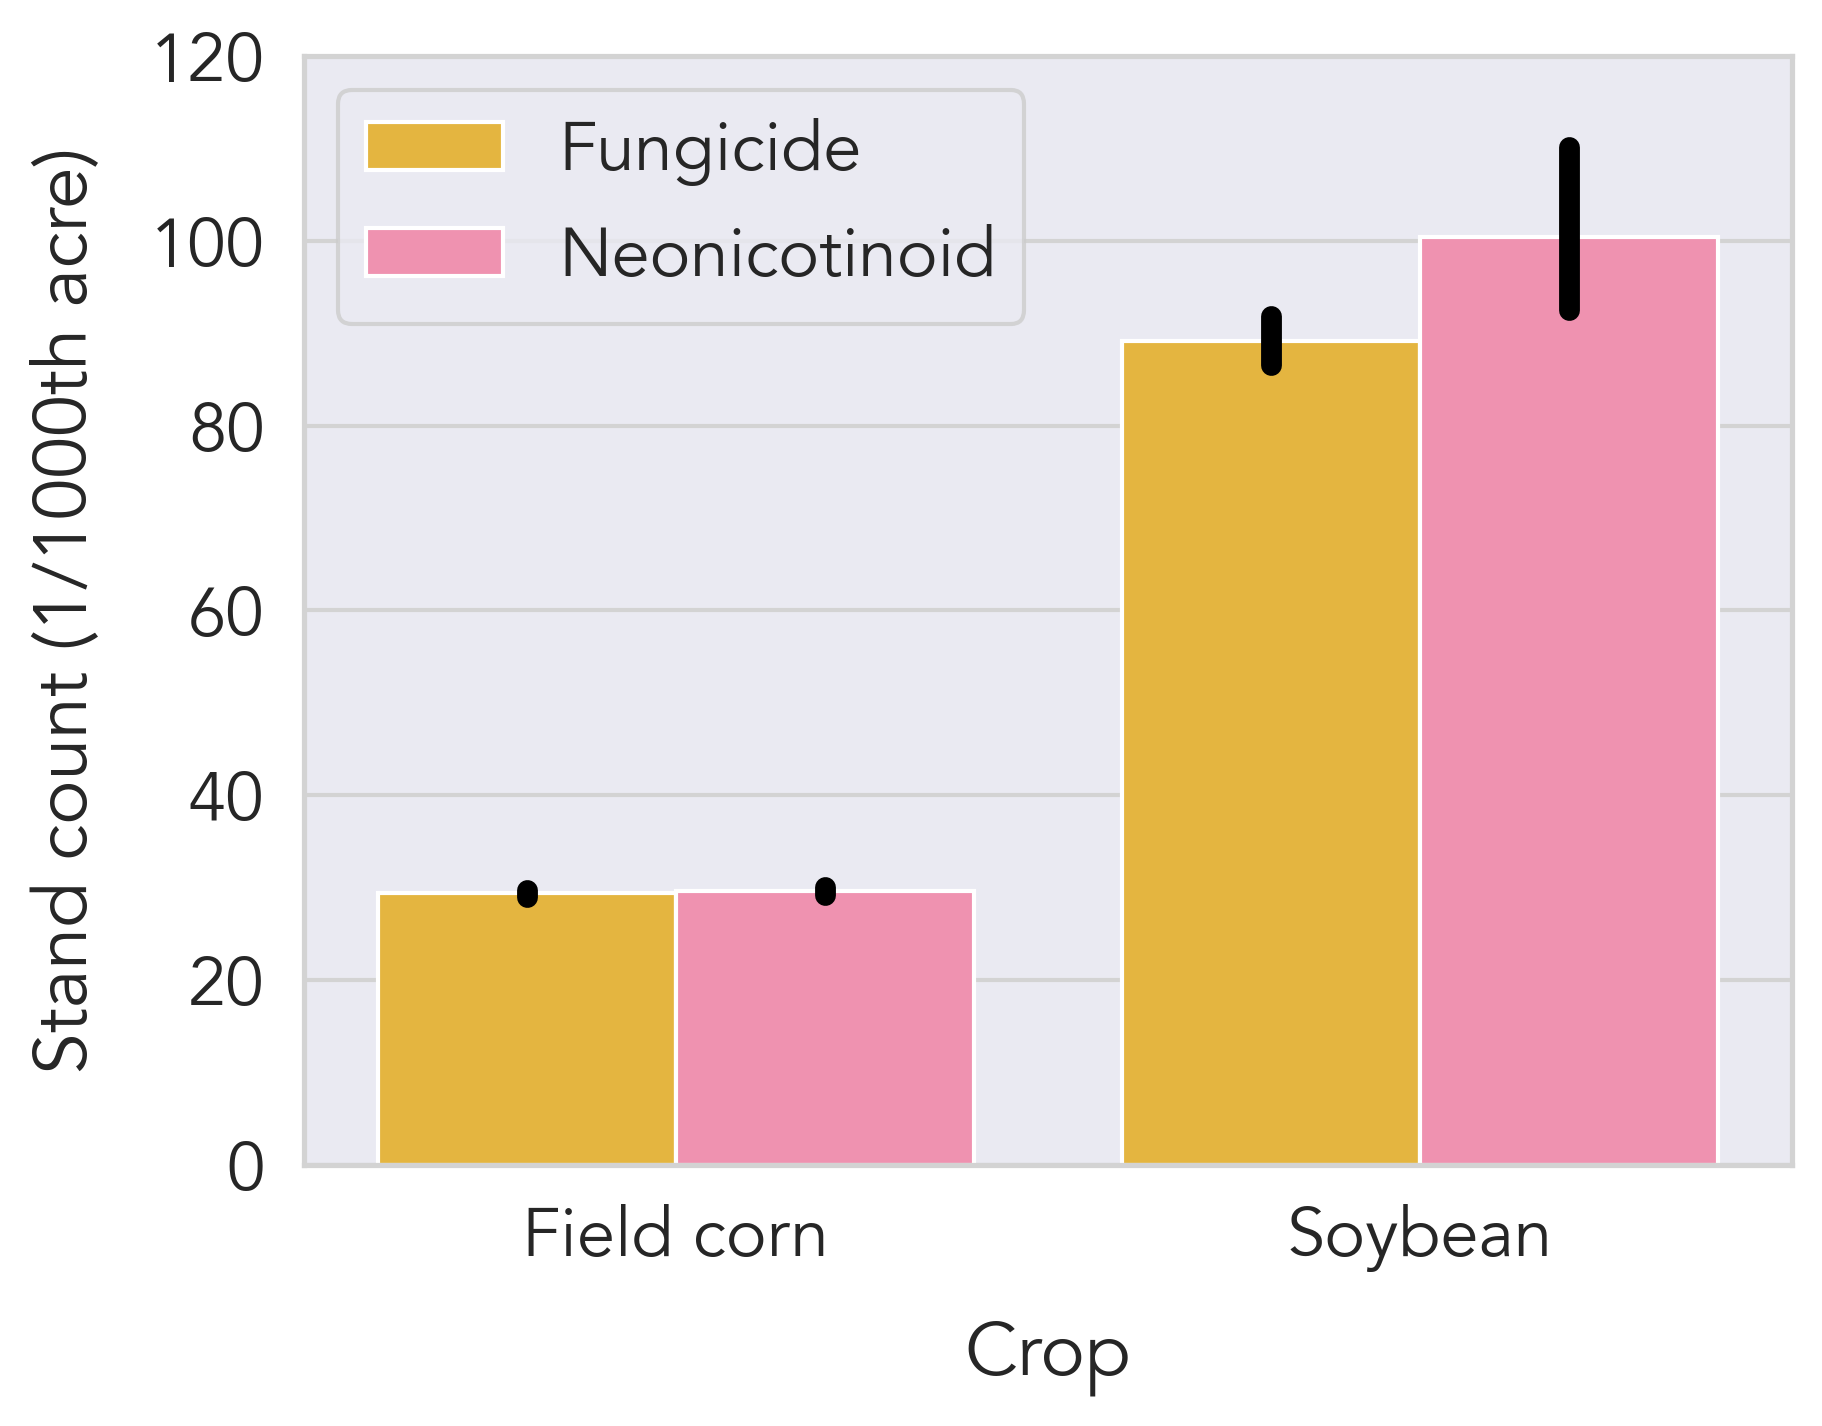

In [435]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})


ax = sns.barplot(
    data=stand_2026,
    x="crop",
    y="stand_count",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)
plt.legend(loc='upper left')

plt.xlabel("Crop", labelpad=10)
plt.ylabel("Stand count (1/1000th acre)", labelpad=10)
plt.ylim(0, 120)
plt.show()


In [436]:
t1 = stand_2026.loc[(stand_2026['treatment'] == 'Neonicotinoid') & (stand_2026['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()
t2 = stand_2026.loc[(stand_2026['treatment'] == 'Fungicide') & (stand_2026['crop'] == 'Field corn')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=0.865662578951551, pvalue=0.3919694076846355, df=39)

In [437]:
t1 = stand_2026.loc[(stand_2026['treatment'] == 'Neonicotinoid') & (stand_2026['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()
t2 = stand_2026.loc[(stand_2026['treatment'] == 'Fungicide') & (stand_2026['crop'] == 'Soybean')].groupby('field_id')['stand_count'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=1.8234324944646765, pvalue=0.08697477883456303, df=16)

In [454]:
biomass_2026 = pd.read_csv('Data/2026/fresh_biomass_2026.csv')
biomass_2026 = clean_columns(biomass_2026)
biomass_2026['treatment'] = biomass_2026['treatment'].replace({'Fung': 'Fungicide', 'Neonic': 'Neonicotinoid'})
biomass_2026 = biomass_2026.loc[(biomass_2026['crop'] == 'Field corn') | (biomass_2026['crop'] == 'Soybean')]


biomass_2026

,data_collector,field_id,date,sampling_period,crop,treatment,section_number,plant_growth_stage,number_of_plants,total_weight_g,notes,untared_weight_g,unnamed_12,unnamed_13
0,Marylynn Collins,KUH_COL,6/8/2026,V3/V4,Field corn,Fungicide,1,V4/V5,15,73.00,NaN,NaN,NaN,NaN
1,Marylynn Collins,KUH_COL,6/8/2026,V3/V4,Field corn,Fungicide,2,V4,15,69.00,Some deer damage,NaN,NaN,NaN
2,Marylynn Collins,KUH_COL,6/8/2026,V3/V4,Field corn,Fungicide,3,V4,15,68.00,NaN,NaN,NaN,NaN
3,Marylynn Collins,KUH_COL,6/8/2026,V3/V4,Field corn,Fungicide,4,V4,15,65.00,NaN,NaN,NaN,NaN
4,Marylynn Collins,KUH_COL,6/8/2026,V3/V4,Field corn,Fungicide,5,V4,15,71.00,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Erik Smith,SMI_CON_2,6/9/2026,V4/V5,Field corn,Fungicide,5,V4/V5,15,133.35,NaN,NaN,NaN,NaN
1301,Erik Smith,SMI_CON_2,6/9/2026,V4/V5,Field corn,Fungicide,6,V4/V5,15,93.26,NaN,NaN,NaN,NaN
1302,Erik Smith,SMI_CON_2,6/9/2026,V4/V5,Field corn,Fungicide,7,V4/V5,15,76.66,NaN,NaN,NaN,NaN
1303,Erik Smith,SMI_CON_2,6/9/2026,V4/V5,Field corn,Fungicide,8,V4/V5,15,119.71,NaN,NaN,NaN,NaN


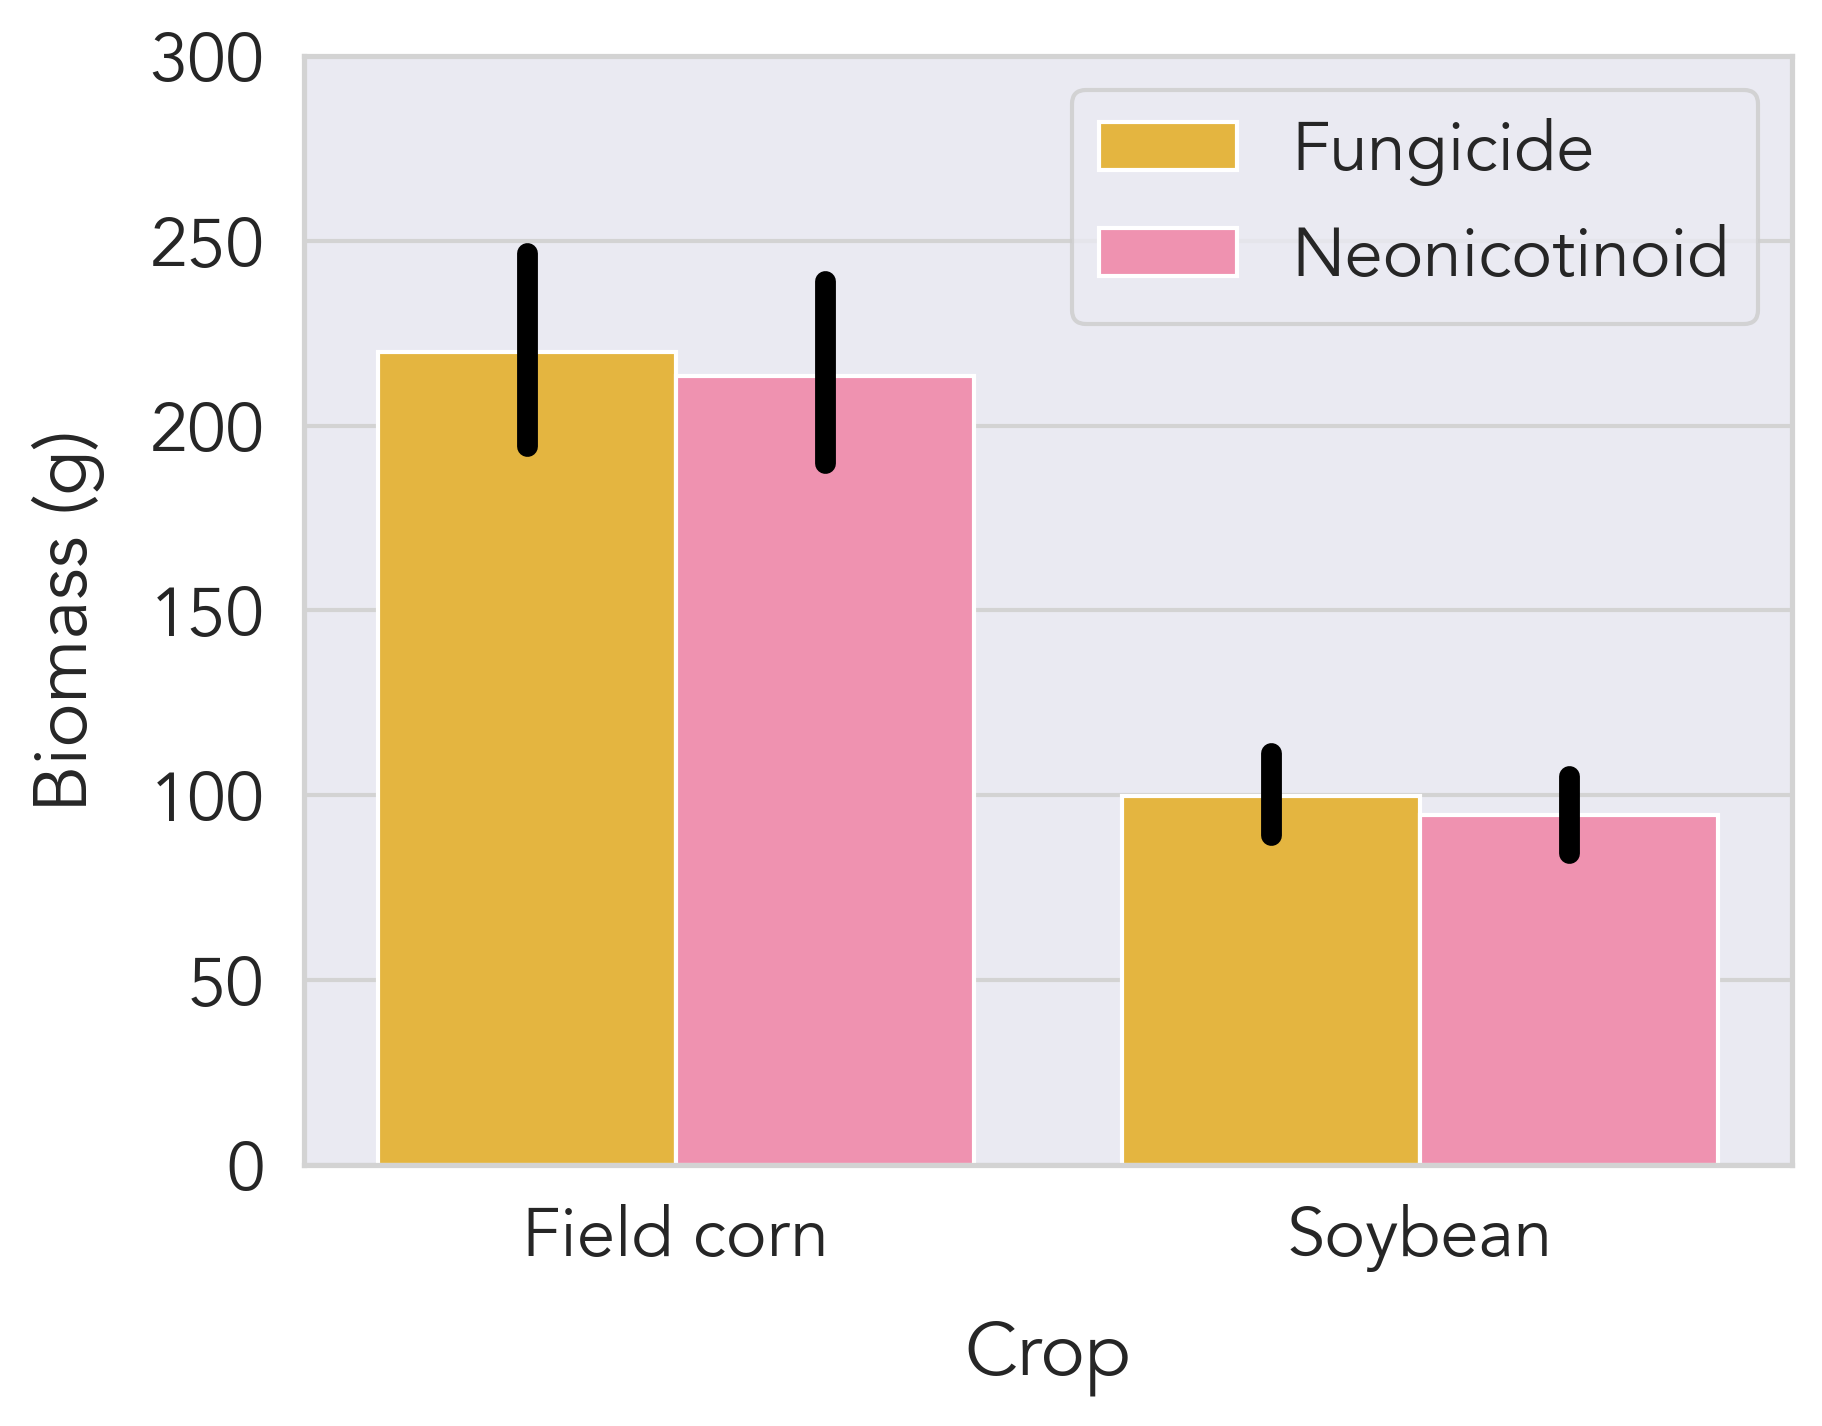

In [456]:
plt.figure()
plt.rcParams.update({"figure.dpi": 300})
sns.set(font="Avenir", font_scale=1.5, rc={'grid.color': 'lightgray', 'axes.edgecolor': 'lightgray', 'legend.frameon':True})

plt.rcParams.update({"font.size": 18})

sns.barplot(
    data=biomass_2026,
    x="crop",
    order=['Field corn', 'Soybean'],
    y="total_weight_g",
    palette=['#FFC125', '#FF82AB'],
    hue_order=["Fungicide", "Neonicotinoid"],
    hue="treatment",
    err_kws={'linewidth': 5, 'color':'black'}
)

ax.legend_.set_title(None)
plt.legend(loc='upper right')

plt.xlabel("Crop", labelpad=10)
plt.ylabel("Biomass (g) ", labelpad=10)
plt.ylim(0, 300)
plt.show()


In [459]:
t1 = biomass_2026.loc[(biomass_2026['treatment'] == 'Neonicotinoid') & (biomass_2026['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2026.loc[(biomass_2026['treatment'] == 'Fungicide') & (biomass_2026['crop'] == 'Field corn')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-0.4417898039958046, pvalue=0.6613590178304616, df=35)

In [457]:
t1 = biomass_2026.loc[(biomass_2026['treatment'] == 'Neonicotinoid') & (biomass_2026['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()
t2 = biomass_2026.loc[(biomass_2026['treatment'] == 'Fungicide') & (biomass_2026['crop'] == 'Soybean')].groupby('field_id')['total_weight_g'].mean()

stats.ttest_rel(t1, t2)

TtestResult(statistic=-0.9571583182158849, pvalue=0.3536610847617251, df=15)

In [460]:
len(biomass_2026.loc[biomass_2026['crop'] == 'Field corn']['field_id'].unique())

36

In [461]:
len(biomass_2026.loc[biomass_2026['crop'] == 'Soybean']['field_id'].unique())

16